In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.model_selection import train_test_split

# --------------------------------------------------
# STEP 1: Locate project directory
# --------------------------------------------------

project_dir = Path.cwd()

if not (project_dir / "datasets" / "processed").exists():
    project_dir = project_dir.parent

# --------------------------------------------------
# STEP 2: Load processed datasets
# --------------------------------------------------

credit_path = (
    project_dir / "datasets" / "processed"
    / "credit_risk_cleaned.csv"
)

donor_path = (
    project_dir / "datasets" / "processed"
    / "financial_risk_inspected.csv"
)

df_credit_full = pd.read_csv(credit_path)
df_donor = pd.read_csv(donor_path)

print("CREDIT RISK DATASET")
print("Shape:", df_credit_full.shape)
print("Missing values:", df_credit_full.isnull().sum().sum())

print("\nFINANCIAL RISK DONOR DATASET")
print("Shape:", df_donor.shape)
print("Missing values:", df_donor.isnull().sum().sum())

# --------------------------------------------------
# STEP 3: Split recipient data BEFORE statistical matching
# --------------------------------------------------

all_indices = np.arange(len(df_credit_full))

train_indices, test_indices = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=42,
    stratify=df_credit_full["loan_status"]
)

df_credit_train = df_credit_full.iloc[train_indices].copy()
df_credit_test = df_credit_full.iloc[test_indices].copy()

# Use training data in the existing EDA and matching cells.
# Keep df_credit_test separate until the frozen matching
# procedure is applied to it.

df_credit = df_credit_train.copy()

print("\nTRAINING DATA")
print("Shape:", df_credit_train.shape)
print(df_credit_train["loan_status"].value_counts().sort_index())

print("\nTEST DATA")
print("Shape:", df_credit_test.shape)
print(df_credit_test["loan_status"].value_counts().sort_index())

print("\nTRAINING DEFAULT RATE:",
      round(df_credit_train["loan_status"].mean() * 100, 2), "%")

print("TEST DEFAULT RATE:",
      round(df_credit_test["loan_status"].mean() * 100, 2), "%")

print("\nDONOR DATASET")
print("Shape:", df_donor.shape)

# Confirm that the split has no overlapping records.
assert set(df_credit_train.index).isdisjoint(
    set(df_credit_test.index)
)

assert len(df_credit_train) + len(df_credit_test) == len(df_credit_full)

print("\nTrain/test split completed successfully.")

CREDIT RISK DATASET
Shape: (32416, 12)
Missing values: 3989

FINANCIAL RISK DONOR DATASET
Shape: (20000, 36)
Missing values: 0

TRAINING DATA
Shape: (25932, 12)
loan_status
0    20261
1     5671
Name: count, dtype: int64

TEST DATA
Shape: (6484, 12)
loan_status
0    5066
1    1418
Name: count, dtype: int64

TRAINING DEFAULT RATE: 21.87 %
TEST DEFAULT RATE: 21.87 %

DONOR DATASET
Shape: (20000, 36)

Train/test split completed successfully.


In [2]:
# Define candidate feature mappings between both datasets

feature_mapping = {
    "person_age": "Age",
    "person_income": "AnnualIncome",
    "person_home_ownership": "HomeOwnershipStatus",
    "loan_intent": "LoanPurpose",
    "loan_amnt": "LoanAmount",
    "loan_int_rate": "InterestRate",
    "person_emp_length": "Experience",
    "cb_person_cred_hist_length": "LengthOfCreditHistory"
}

# Identify the variables actually used for matching
actual_matching_features = {
    "person_age": "Age",
    "person_income": "AnnualIncome",
    "person_home_ownership": "HomeOwnershipStatus"
}

mapping_df = pd.DataFrame(
    [
        {
            "Credit_Risk_Feature": credit_col,
            "Donor_Feature": donor_col,
            "Role": (
                "Used for matching"
                if credit_col in actual_matching_features
                else "Candidate mapping only"
            )
        }
        for credit_col, donor_col in feature_mapping.items()
    ]
)

display(mapping_df)

print(
    "\nNumber of candidate mappings:",
    len(feature_mapping)
)

print(
    "Number of actual matching variables:",
    len(actual_matching_features)
)

,Credit_Risk_Feature,Donor_Feature,Role
0,person_age,Age,Used for matching
1,person_income,AnnualIncome,Used for matching
2,person_home_ownership,HomeOwnershipStatus,Used for matching
3,loan_intent,LoanPurpose,Candidate mapping only
4,loan_amnt,LoanAmount,Candidate mapping only
5,loan_int_rate,InterestRate,Candidate mapping only
6,person_emp_length,Experience,Candidate mapping only
7,cb_person_cred_hist_length,LengthOfCreditHistory,Candidate mapping only



Number of candidate mappings: 8
Number of actual matching variables: 3


In [3]:
# Numerical feature comparison with consistent units

numerical_mapping = {
    "person_age": "Age",
    "person_income": "AnnualIncome",
    "loan_amnt": "LoanAmount",
    "loan_int_rate": "InterestRate",
    "person_emp_length": "Experience",
    "cb_person_cred_hist_length": "LengthOfCreditHistory"
}

comparison = []

for credit_col, donor_col in numerical_mapping.items():

    credit_values = df_credit[credit_col].dropna()
    donor_values = df_donor[donor_col].dropna()

    # Convert donor interest rate from decimal to percentage
    if credit_col == "loan_int_rate":
        donor_values = donor_values * 100

    comparison.append({
        "Credit_Feature": credit_col,
        "Donor_Feature": donor_col,

        "Credit_Mean": credit_values.mean(),
        "Donor_Mean": donor_values.mean(),

        "Credit_Median": credit_values.median(),
        "Donor_Median": donor_values.median(),

        "Credit_Min": credit_values.min(),
        "Donor_Min": donor_values.min(),

        "Credit_Max": credit_values.max(),
        "Donor_Max": donor_values.max()
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(2))

,Credit_Feature,Donor_Feature,Credit_Mean,Donor_Mean,Credit_Median,Donor_Median,Credit_Min,Donor_Min,Credit_Max,Donor_Max
0,person_age,Age,27.71,39.75,26.00,40.00,20.00,18.00,94.00,80.00
1,person_income,AnnualIncome,65828.51,59161.47,55000.00,48566.00,4000.00,15000.00,6000000.00,485341.00
2,loan_amnt,LoanAmount,9592.17,24882.87,8000.00,21914.50,500.00,3674.00,35000.00,184732.00
3,loan_int_rate,InterestRate,11.02,23.91,10.99,23.54,5.42,11.33,23.22,44.68
4,person_emp_length,Experience,4.76,17.52,4.00,17.00,0.00,0.00,38.00,61.00
5,cb_person_cred_hist_length,LengthOfCreditHistory,5.80,14.96,4.00,15.00,2.00,1.00,30.00,29.00


In [4]:
# Compare distributions using percentiles

numerical_mapping = {
    'person_age': 'Age',
    'person_income': 'AnnualIncome',
    'loan_amnt': 'LoanAmount',
    'loan_int_rate': 'InterestRate',
    'person_emp_length': 'Experience',
    'cb_person_cred_hist_length': 'LengthOfCreditHistory'
}

percentiles = [0.10, 0.25, 0.50, 0.75, 0.90]

overlap_results = []

for credit_col, donor_col in numerical_mapping.items():

    credit_values = df_credit[credit_col].dropna()
    donor_values = df_donor[donor_col].dropna()

    # Convert donor interest rates from decimals to percentages
    if credit_col == 'loan_int_rate':
        donor_values = donor_values * 100

    # Determine shared numerical range
    lower_bound = max(
        credit_values.min(),
        donor_values.min()
    )

    upper_bound = min(
        credit_values.max(),
        donor_values.max()
    )

    # Calculate percentage within shared range
    credit_overlap = (
        credit_values.between(lower_bound, upper_bound).mean() * 100
    )

    donor_overlap = (
        donor_values.between(lower_bound, upper_bound).mean() * 100
    )

    result = {
        'Feature': credit_col,
        'Shared_Min': lower_bound,
        'Shared_Max': upper_bound,
        'Credit_Overlap_%': credit_overlap,
        'Donor_Overlap_%': donor_overlap
    }

    # Add percentile comparisons
    for p in percentiles:
        result[f'Credit_P{int(p*100)}'] = credit_values.quantile(p)
        result[f'Donor_P{int(p*100)}'] = donor_values.quantile(p)

    overlap_results.append(result)

overlap_df = pd.DataFrame(overlap_results)

display(overlap_df.round(2))

,Feature,Shared_Min,Shared_Max,Credit_Overlap_%,Donor_Overlap_%,Credit_P10,Donor_P10,Credit_P25,Donor_P25,Credit_P50,Donor_P50,Credit_P75,Donor_P75,Credit_P90,Donor_P90
0,person_age,20.00,80.00,99.99,95.28,22.00,24.00,23.0,32.00,26.00,40.00,30.00,48.00,36.00,55.00
1,person_income,15000.00,485341.00,98.59,100.00,28800.00,21819.30,38400.0,31679.00,55000.00,48566.00,78643.75,74391.00,110000.00,108347.50
2,loan_amnt,3674.00,35000.00,84.82,82.44,3000.00,11465.80,5000.0,15575.00,8000.00,21914.50,12250.00,30835.00,19000.00,41997.20
3,loan_int_rate,11.33,23.22,46.95,47.08,6.91,18.77,7.9,20.91,10.99,23.54,13.48,26.55,15.31,29.54
4,person_emp_length,0.00,38.00,100.00,96.06,0.00,2.00,2.0,9.00,4.00,17.00,7.00,25.00,10.00,33.00
5,cb_person_cred_hist_length,2.00,29.00,99.93,96.34,2.00,3.00,3.0,8.00,4.00,15.00,8.00,22.00,11.00,27.00


In [5]:
# Compare categorical feature distributions

categorical_mapping = {
    'person_home_ownership': 'HomeOwnershipStatus',
    'loan_intent': 'LoanPurpose'
}

for credit_col, donor_col in categorical_mapping.items():

    print("\n" + "=" * 60)
    print(f"CREDIT FEATURE: {credit_col}")
    print(f"DONOR FEATURE: {donor_col}")
    print("=" * 60)

    print("\nCREDIT RISK DISTRIBUTION:")

    print(
        df_credit[credit_col]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

    print("\nFINANCIAL RISK DONOR DISTRIBUTION:")

    print(
        df_donor[donor_col]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )


CREDIT FEATURE: person_home_ownership
DONOR FEATURE: HomeOwnershipStatus

CREDIT RISK DISTRIBUTION:
person_home_ownership
RENT        50.57
MORTGAGE    41.22
OWN          7.87
OTHER        0.34
Name: proportion, dtype: float64

FINANCIAL RISK DONOR DISTRIBUTION:
HomeOwnershipStatus
Mortgage    39.70
Rent        30.44
Own         19.69
Other       10.18
Name: proportion, dtype: float64

CREDIT FEATURE: loan_intent
DONOR FEATURE: LoanPurpose

CREDIT RISK DISTRIBUTION:
loan_intent
EDUCATION            19.76
MEDICAL              18.67
VENTURE              17.78
PERSONAL             16.80
DEBTCONSOLIDATION    16.12
HOMEIMPROVEMENT      10.88
Name: proportion, dtype: float64

FINANCIAL RISK DONOR DISTRIBUTION:
LoanPurpose
Home                  29.62
Debt Consolidation    25.14
Auto                  20.17
Education             15.04
Other                 10.03
Name: proportion, dtype: float64


In [6]:
# Initial matching variables
credit_matching_cols = [
    'person_age',
    'person_income',
    'person_home_ownership'
]

donor_matching_cols = [
    'Age',
    'AnnualIncome',
    'HomeOwnershipStatus'
]

print("CREDIT RISK - MISSING VALUES")
print(df_credit[credit_matching_cols].isnull().sum())

print("\nFINANCIAL RISK - MISSING VALUES")
print(df_donor[donor_matching_cols].isnull().sum())

print("\nCREDIT RISK - HOME OWNERSHIP CATEGORIES")
print(sorted(df_credit['person_home_ownership'].dropna().unique()))

print("\nDONOR - HOME OWNERSHIP CATEGORIES")
print(sorted(df_donor['HomeOwnershipStatus'].dropna().unique()))

CREDIT RISK - MISSING VALUES
person_age               5
person_income            0
person_home_ownership    0
dtype: int64

FINANCIAL RISK - MISSING VALUES
Age                    0
AnnualIncome           0
HomeOwnershipStatus    0
dtype: int64

CREDIT RISK - HOME OWNERSHIP CATEGORIES
['MORTGAGE', 'OTHER', 'OWN', 'RENT']

DONOR - HOME OWNERSHIP CATEGORIES
['Mortgage', 'Other', 'Own', 'Rent']


In [7]:
# Create separate matching datasets
credit_match = df_credit[
    ['person_age', 'person_income', 'person_home_ownership']
].copy()

donor_match = df_donor[
    ['Age', 'AnnualIncome', 'HomeOwnershipStatus']
].copy()


# Normalize home ownership categories
credit_match['home_ownership'] = (
    credit_match['person_home_ownership'].str.upper()
)

donor_match['home_ownership'] = (
    donor_match['HomeOwnershipStatus'].str.upper()
)


# Transform income to reduce right-skewness
credit_match['log_income'] = np.log1p(
    credit_match['person_income']
)

donor_match['log_income'] = np.log1p(
    donor_match['AnnualIncome']
)


# Exclude records with missing age from matching only
credit_match_valid = credit_match.dropna(
    subset=['person_age']
).copy()


print("CREDIT MATCHING DATA")
print("Original records:", len(credit_match))
print("Records available for matching:", len(credit_match_valid))
print("Excluded due to missing age:", credit_match['person_age'].isna().sum())

print("\nDONOR MATCHING DATA")
print("Available donor records:", len(donor_match))


print("\nHOME OWNERSHIP COUNTS IN CREDIT DATA")
print(credit_match_valid['home_ownership'].value_counts())

print("\nHOME OWNERSHIP COUNTS IN DONOR DATA")
print(donor_match['home_ownership'].value_counts())


print("\nTRANSFORMED INCOME COMPARISON")
print("Credit Risk log income:")
print(credit_match_valid['log_income'].describe().round(2))

print("\nDonor log income:")
print(donor_match['log_income'].describe().round(2))

CREDIT MATCHING DATA
Original records: 25932
Records available for matching: 25927
Excluded due to missing age: 5

DONOR MATCHING DATA
Available donor records: 20000

HOME OWNERSHIP COUNTS IN CREDIT DATA
home_ownership
RENT        13111
MORTGAGE    10686
OWN          2042
OTHER          88
Name: count, dtype: int64

HOME OWNERSHIP COUNTS IN DONOR DATA
home_ownership
MORTGAGE    7939
RENT        6087
OWN         3938
OTHER       2036
Name: count, dtype: int64

TRANSFORMED INCOME COMPARISON
Credit Risk log income:
count    25927.00
mean        10.92
std          0.56
min          8.29
25%         10.56
50%         10.92
75%         11.27
max         14.53
Name: log_income, dtype: float64

Donor log income:
count    20000.00
mean        10.80
std          0.61
min          9.62
25%         10.36
50%         10.79
75%         11.22
max         13.09
Name: log_income, dtype: float64


In [8]:

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

# 1. Prepare numerical matching features
credit_features = (
    credit_match_valid[['person_age', 'log_income']]
    .rename(columns={'person_age': 'Age'})
)

donor_features = donor_match[['Age', 'log_income']]

# 2. Fit scaler on donor data
scaler = StandardScaler()

donor_scaled = scaler.fit_transform(donor_features)

credit_scaled = scaler.transform(credit_features)

# 3. Store matching results
matching_results = []

# 4. Match separately within each home ownership category
for category in credit_match_valid['home_ownership'].unique():

    credit_indices = credit_match_valid[
        credit_match_valid['home_ownership'] == category
    ].index

    donor_indices = donor_match[
        donor_match['home_ownership'] == category
    ].index

    # Get standardized data for this category
    credit_category_scaled = credit_scaled[
        credit_match_valid.index.get_indexer(credit_indices)
    ]

    donor_category_scaled = donor_scaled[
        donor_match.index.get_indexer(donor_indices)
    ]

    # Find five nearest donors
    knn = NearestNeighbors(
        n_neighbors=5,
        metric='euclidean'
    )

    knn.fit(donor_category_scaled)

    distances, neighbor_positions = knn.kneighbors(
        credit_category_scaled
    )

    # Store recipient and donor information
    for i, credit_idx in enumerate(credit_indices):

        for rank in range(5):

            donor_position = neighbor_positions[i, rank]
            donor_idx = donor_indices[donor_position]

            matching_results.append({
                'credit_index': credit_idx,
                'donor_index': donor_idx,
                'home_ownership': category,
                'neighbor_rank': rank + 1,
                'distance': distances[i, rank]
            })

# 5. Convert results into DataFrame
matching_df = pd.DataFrame(matching_results)

print("Total matching records:", len(matching_df))
print("Expected records:", len(credit_match_valid) * 5)

print("\nNEAREST DONOR DISTANCE SUMMARY")

print(
    matching_df[matching_df['neighbor_rank'] == 1]
    ['distance']
    .describe()
    .round(4)
)

print("\nDISTANCE SUMMARY BY HOME OWNERSHIP")

print(
    matching_df[matching_df['neighbor_rank'] == 1]
    .groupby('home_ownership')['distance']
    .agg(['count', 'mean', 'median', 'max'])
    .round(4)
)


Total matching records: 129635
Expected records: 129635

NEAREST DONOR DISTANCE SUMMARY
count    25927.0000
mean         0.0278
std          0.0913
min          0.0000
25%          0.0043
50%          0.0109
75%          0.0265
max          2.7313
Name: distance, dtype: float64

DISTANCE SUMMARY BY HOME OWNERSHIP
                count    mean  median     max
home_ownership                               
MORTGAGE        10686  0.0252  0.0102  2.4708
OTHER              88  0.0707  0.0453  1.1392
OWN              2042  0.0385  0.0172  1.8374
RENT            13111  0.0280  0.0105  2.7313


In [9]:
# Keep only the closest donor for each recipient
nearest_matches = matching_df[
    matching_df['neighbor_rank'] == 1
].copy()

# Count how many times each donor is selected
donor_usage = (
    nearest_matches['donor_index']
    .value_counts()
    .reindex(donor_match.index, fill_value=0)
)

# Summary of donor reuse
print("DONOR REUSE SUMMARY")

print("Total donor records:", len(donor_usage))
print("Donors used at least once:", (donor_usage > 0).sum())
print("Donors never used:", (donor_usage == 0).sum())

print("\nReuse frequency statistics:")
print(donor_usage.describe().round(2))

print("\nMaximum times a donor was reused:")
print(donor_usage.max())

print("\nTop 10 most frequently selected donors:")
print(donor_usage.sort_values(ascending=False).head(10))


# Check reuse separately by ownership category
reuse_by_category = nearest_matches.groupby(
    'home_ownership'
)['donor_index'].value_counts()

print("\nNUMBER OF UNIQUE DONORS USED BY OWNERSHIP")
print(
    nearest_matches.groupby('home_ownership')['donor_index']
    .nunique()
)

DONOR REUSE SUMMARY
Total donor records: 20000
Donors used at least once: 4972
Donors never used: 15028

Reuse frequency statistics:
count    20000.00
mean         1.30
std          4.96
min          0.00
25%          0.00
50%          0.00
75%          0.00
max        101.00
Name: count, dtype: float64

Maximum times a donor was reused:
101

Top 10 most frequently selected donors:
5394     101
3739      98
12859     93
6111      92
8531      90
18925     85
17064     85
17849     81
13757     79
9096      78
Name: count, dtype: int64

NUMBER OF UNIQUE DONORS USED BY OWNERSHIP
home_ownership
MORTGAGE    2021
OTHER         68
OWN          799
RENT        2084
Name: donor_index, dtype: int64


In [10]:
# 1. Get the nearest match for each recipient
nearest_matches = matching_df[
    matching_df['neighbor_rank'] == 1
].copy()

# 2. Sort recipients by matching distance
worst_matches = nearest_matches.sort_values(
    'distance',
    ascending=False
).head(20)

# 3. Collect recipient and donor details
worst_match_details = []

for _, match in worst_matches.iterrows():

    credit_idx = match['credit_index']
    donor_idx = match['donor_index']

    credit_record = credit_match_valid.loc[credit_idx]
    donor_record = donor_match.loc[donor_idx]

    worst_match_details.append({
        'credit_index': credit_idx,
        'donor_index': donor_idx,
        'home_ownership': match['home_ownership'],
        'distance': match['distance'],
        'credit_age': credit_record['person_age'],
        'donor_age': donor_record['Age'],
        'credit_income': credit_record['person_income'],
        'donor_income': donor_record['AnnualIncome']
    })

worst_match_details = pd.DataFrame(worst_match_details)

print("20 RECIPIENTS WITH THE WORST NEAREST-DONOR MATCHES")

print(
    worst_match_details.round(3).to_string(index=False)
)

# 4. Inspect distance percentiles
print("\nNEAREST MATCH DISTANCE PERCENTILES")

print(
    nearest_matches['distance']
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99, 1.00])
    .round(4)
)

20 RECIPIENTS WITH THE WORST NEAREST-DONOR MATCHES
 credit_index  donor_index home_ownership  distance  credit_age  donor_age  credit_income  donor_income
        32332         1499           RENT     2.731        63.0         47        1782000        422480
        29890         1499           RENT     2.616        42.0         47        2039784        422480
        31765         4374       MORTGAGE     2.471        44.0         51        1440000        333715
        31763         4374       MORTGAGE     2.331        47.0         51        1362000        333715
        28961        19600       MORTGAGE     2.207        40.0         36        1200000        317379
        17711        19600       MORTGAGE     2.207        32.0         36        1200000        317379
        31771        13639           RENT     2.166        41.0         41           4000         15000
        15964         7552           RENT     2.133        21.0         21           4080         15000
        15963

In [11]:
# Donor dataset's observed numerical ranges
donor_age_min = donor_match['Age'].min()
donor_age_max = donor_match['Age'].max()

donor_income_min = donor_match['AnnualIncome'].min()
donor_income_max = donor_match['AnnualIncome'].max()


# Check whether each Credit Risk record falls within donor ranges
support_check = credit_match_valid.copy()

support_check['age_in_range'] = (
    support_check['person_age'].between(
        donor_age_min, donor_age_max
    )
)

support_check['income_in_range'] = (
    support_check['person_income'].between(
        donor_income_min, donor_income_max
    )
)

support_check['both_in_range'] = (
    support_check['age_in_range'] &
    support_check['income_in_range']
)


print("DONOR SUPPORT RANGES")
print(f"Age: {donor_age_min} to {donor_age_max}")
print(f"Annual income: {donor_income_min:,.0f} to {donor_income_max:,.0f}")


print("\nCREDIT RISK RECORDS OUTSIDE DONOR RANGES")

for column in ['age_in_range', 'income_in_range', 'both_in_range']:

    outside_count = (~support_check[column]).sum()

    print(
        f"{column}: "
        f"{outside_count:,} outside "
        f"({outside_count / len(support_check) * 100:.2f}%)"
    )


print("\nDETAILED COMMON SUPPORT COUNTS")

print(
    support_check.groupby('home_ownership')[
        ['age_in_range', 'income_in_range', 'both_in_range']
    ].agg(['sum', 'count'])
)


print("\nINCOME RANGE VIOLATIONS")

print(
    "Below donor minimum:",
    (support_check['person_income'] < donor_income_min).sum()
)

print(
    "Above donor maximum:",
    (support_check['person_income'] > donor_income_max).sum()
)

DONOR SUPPORT RANGES
Age: 18 to 80
Annual income: 15,000 to 485,341

CREDIT RISK RECORDS OUTSIDE DONOR RANGES
age_in_range: 2 outside (0.01%)
income_in_range: 365 outside (1.41%)
both_in_range: 367 outside (1.42%)

DETAILED COMMON SUPPORT COUNTS
               age_in_range        income_in_range        both_in_range       
                        sum  count             sum  count           sum  count
home_ownership                                                                
MORTGAGE              10685  10686           10650  10686         10649  10686
OTHER                    88     88              86     88            86     88
OWN                    2042   2042            1981   2042          1981   2042
RENT                  13110  13111           12845  13111         12844  13111

INCOME RANGE VIOLATIONS
Below donor minimum: 322
Above donor maximum: 43


In [12]:

# Inspect the differences between each recipient and their nearest donor

nearest_matches = matching_df[
    matching_df['neighbor_rank'] == 1
].copy()

# Attach recipient and donor values to the matching results
nearest_matches['credit_age'] = nearest_matches['credit_index'].map(
    credit_match_valid['person_age']
)

nearest_matches['donor_age'] = nearest_matches['donor_index'].map(
    donor_match['Age']
)

nearest_matches['credit_income'] = nearest_matches['credit_index'].map(
    credit_match_valid['person_income']
)

nearest_matches['donor_income'] = nearest_matches['donor_index'].map(
    donor_match['AnnualIncome']
)

# Calculate absolute differences
nearest_matches['age_gap'] = (
    nearest_matches['credit_age'] - nearest_matches['donor_age']
).abs()

nearest_matches['income_gap'] = (
    nearest_matches['credit_income'] - nearest_matches['donor_income']
).abs()

# Calculate income difference as a percentage of recipient income
nearest_matches['income_gap_percent'] = (
    nearest_matches['income_gap'] /
    nearest_matches['credit_income'] * 100
)

# Calculate absolute log-income difference
nearest_matches['log_income_gap'] = nearest_matches['credit_index'].map(
    credit_match_valid['log_income']
) - nearest_matches['donor_index'].map(
    donor_match['log_income']
)

nearest_matches['log_income_gap'] = nearest_matches[
    'log_income_gap'
].abs()


# Overall matching difference summary
print("AGE DIFFERENCE SUMMARY")

print(
    nearest_matches['age_gap']
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
    .round(3)
)

print("\nINCOME DIFFERENCE SUMMARY")

print(
    nearest_matches['income_gap']
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
    .round(2)
)

print("\nINCOME PERCENTAGE DIFFERENCE SUMMARY")

print(
    nearest_matches['income_gap_percent']
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
    .round(2)
)

print("\nLOG-INCOME DIFFERENCE SUMMARY")

print(
    nearest_matches['log_income_gap']
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
    .round(4)
)


# Compare matching differences across home-ownership groups
print("\nMATCHING DIFFERENCES BY HOME OWNERSHIP")

print(
    nearest_matches.groupby('home_ownership')[
        ['age_gap', 'income_gap_percent', 'log_income_gap', 'distance']
    ]
    .agg(['median', 'mean', 'max'])
    .round(3)
)


# Inspect the 15 pairs with the largest relative income differences
print("\n15 MATCHES WITH THE LARGEST RELATIVE INCOME DIFFERENCES")

print(
    nearest_matches.sort_values(
        'income_gap_percent',
        ascending=False
    )[
        [
            'credit_index',
            'donor_index',
            'home_ownership',
            'credit_age',
            'donor_age',
            'credit_income',
            'donor_income',
            'age_gap',
            'income_gap_percent',
            'distance'
        ]
    ]
    .head(15)
    .round(3)
    .to_string(index=False)
)


AGE DIFFERENCE SUMMARY
count    25927.000
mean         0.048
std          0.336
min          0.000
50%          0.000
75%          0.000
90%          0.000
95%          0.000
99%          1.000
max         17.000
Name: age_gap, dtype: float64

INCOME DIFFERENCE SUMMARY
count      25927.00
mean        1751.52
std        22383.13
min            0.00
50%          330.00
75%          860.00
90%         2097.00
95%         3571.00
99%        10647.00
max      1617304.00
Name: income_gap, dtype: float64

INCOME PERCENTAGE DIFFERENCE SUMMARY
count    25927.00
mean         1.59
std          6.49
min          0.00
50%          0.64
75%          1.48
90%          2.94
95%          4.12
99%         19.95
max        275.00
Name: income_gap_percent, dtype: float64

LOG-INCOME DIFFERENCE SUMMARY
count    25927.0000
mean         0.0154
std          0.0533
min          0.0000
50%          0.0064
75%          0.0148
90%          0.0296
95%          0.0408
99%          0.1936
max          1.5745
Name: l

In [13]:

# Add common-support information to each recipient's nearest match

nearest_matches['income_in_range'] = nearest_matches['credit_index'].map(
    support_check['income_in_range']
)

nearest_matches['age_in_range'] = nearest_matches['credit_index'].map(
    support_check['age_in_range']
)

nearest_matches['both_in_range'] = nearest_matches['credit_index'].map(
    support_check['both_in_range']
)

# Create descriptive groups
nearest_matches['support_group'] = np.where(
    nearest_matches['both_in_range'],
    'Within common support',
    'Outside common support'
)

# Compare match quality between the two groups
print("MATCH QUALITY: WITHIN VS OUTSIDE COMMON SUPPORT")

support_quality = nearest_matches.groupby('support_group').agg(
    records=('credit_index', 'count'),
    median_distance=('distance', 'median'),
    mean_distance=('distance', 'mean'),
    p90_distance=('distance', lambda x: x.quantile(0.90)),
    max_distance=('distance', 'max'),
    median_income_gap_percent=('income_gap_percent', 'median'),
    mean_income_gap_percent=('income_gap_percent', 'mean'),
    max_income_gap_percent=('income_gap_percent', 'max'),
    median_age_gap=('age_gap', 'median'),
    max_age_gap=('age_gap', 'max')
)

print(support_quality.round(3))


# Inspect the worst matches among records inside common support
print("\n10 WORST MATCHES WITHIN COMMON SUPPORT")

print(
    nearest_matches[
        nearest_matches['both_in_range']
    ]
    .sort_values('distance', ascending=False)[
        [
            'credit_index',
            'donor_index',
            'home_ownership',
            'credit_age',
            'donor_age',
            'credit_income',
            'donor_income',
            'age_gap',
            'income_gap_percent',
            'distance'
        ]
    ]
    .head(10)
    .round(3)
    .to_string(index=False)
)


# Inspect all matches outside common support
print("\nMATCHES OUTSIDE COMMON SUPPORT")

print(
    nearest_matches[
        ~nearest_matches['both_in_range']
    ][
        [
            'credit_index',
            'donor_index',
            'home_ownership',
            'credit_age',
            'donor_age',
            'credit_income',
            'donor_income',
            'age_in_range',
            'income_in_range',
            'age_gap',
            'income_gap_percent',
            'distance'
        ]
    ]
    .sort_values('distance', ascending=False)
    .round(3)
    .to_string(index=False)
)


MATCH QUALITY: WITHIN VS OUTSIDE COMMON SUPPORT
                        records  median_distance  mean_distance  p90_distance  \
support_group                                                                   
Outside common support      367            0.366          0.532         1.215   
Within common support     25560            0.011          0.021         0.053   

                        max_distance  median_income_gap_percent  \
support_group                                                     
Outside common support         2.731                     25.000   
Within common support          0.844                      0.617   

                        mean_income_gap_percent  max_income_gap_percent  \
support_group                                                             
Outside common support                   35.500                   275.0   
Within common support                     1.102                    37.5   

                        median_age_gap  max_age_gap  
sup

In [14]:

# Candidate donor features for statistical data fusion

candidate_features = [
    'CreditScore',
    'CreditCardUtilizationRate',
    'BankruptcyHistory',
    'PreviousLoanDefaults',
    'NumberOfOpenCreditLines',
    'NumberOfCreditInquiries',
    'PaymentHistory',
    'TotalAssets',
    'TotalLiabilities',
    'SavingsAccountBalance',
    'CheckingAccountBalance'
]

# Check data types and missing values
candidate_summary = pd.DataFrame({
    'Data Type': df_donor[candidate_features].dtypes.astype(str),
    'Missing Values': df_donor[candidate_features].isna().sum(),
    'Unique Values': df_donor[candidate_features].nunique(),
    'Mean': df_donor[candidate_features].mean(),
    'Median': df_donor[candidate_features].median(),
    'Minimum': df_donor[candidate_features].min(),
    'Maximum': df_donor[candidate_features].max(),
    'Std': df_donor[candidate_features].std()
})

print("CANDIDATE DONOR FEATURE SUMMARY")
print(candidate_summary.round(3).to_string())


# Check binary feature distributions
binary_features = [
    'BankruptcyHistory',
    'PreviousLoanDefaults'
]

print("\nBINARY FEATURE DISTRIBUTIONS")

for column in binary_features:
    print(f"\n{column}")
    print(df_donor[column].value_counts(normalize=True).mul(100).round(2))


# Check correlations between candidate numerical features
print("\nHIGH CORRELATIONS AMONG CANDIDATE FEATURES")

candidate_corr = df_donor[candidate_features].corr(method='spearman')

for i in range(len(candidate_features)):
    for j in range(i + 1, len(candidate_features)):
        correlation = candidate_corr.iloc[i, j]

        if abs(correlation) >= 0.70:
            print(
                f"{candidate_features[i]} vs "
                f"{candidate_features[j]}: {correlation:.3f}"
            )


CANDIDATE DONOR FEATURE SUMMARY
                          Data Type  Missing Values  Unique Values       Mean     Median   Minimum      Maximum         Std
CreditScore                   int64               0            322    571.612    578.000   343.000      712.000      50.997
CreditCardUtilizationRate   float64               0          20000      0.286      0.267     0.001        0.917       0.160
BankruptcyHistory             int64               0              2      0.052      0.000     0.000        1.000       0.223
PreviousLoanDefaults          int64               0              2      0.100      0.000     0.000        1.000       0.300
NumberOfOpenCreditLines       int64               0             14      3.023      3.000     0.000       13.000       1.736
NumberOfCreditInquiries       int64               0              8      0.993      1.000     0.000        7.000       0.987
PaymentHistory                int64               0             38     23.994     24.000     8.000  

In [15]:

# Check how much the five nearest donors differ
# for each candidate feature.

donor_neighbor_values = matching_df[
    ['credit_index', 'donor_index', 'neighbor_rank']
].copy()

# Attach all candidate donor features
for feature in candidate_features:
    donor_neighbor_values[feature] = (
        donor_neighbor_values['donor_index']
        .map(df_donor[feature])
    )

# Calculate variation among the five donors for each recipient
neighbor_variation = donor_neighbor_values.groupby('credit_index')[
    candidate_features
].agg(['mean', 'std', 'min', 'max'])

print("VARIATION AMONG FIVE NEAREST DONORS")

for feature in candidate_features:
    feature_std = neighbor_variation[(feature, 'std')]

    print(f"\n{feature}")
    print("Median within-neighbour standard deviation:",
          round(feature_std.median(), 4))
    print("90th percentile within-neighbour standard deviation:",
          round(feature_std.quantile(0.90), 4))
    print("Maximum within-neighbour standard deviation:",
          round(feature_std.max(), 4))


# For binary variables, calculate the proportion of neighbours
# having value 1 for each recipient.
print("\nBINARY FEATURE AGREEMENT")

for feature in ['BankruptcyHistory', 'PreviousLoanDefaults']:

    proportions = donor_neighbor_values.groupby('credit_index')[
        feature
    ].mean()

    print(f"\n{feature}")
    print("All five agree on 0:",
          (proportions == 0).sum())
    print("All five agree on 1:",
          (proportions == 1).sum())
    print("Mixed values:",
          ((proportions > 0) & (proportions < 1)).sum())
    print("Mean proportion of 1:",
          round(proportions.mean(), 4))


# Show examples where the five neighbours disagree most
print("\nEXAMPLES OF HIGH DISAGREEMENT")

for feature in ['CreditScore', 'CreditCardUtilizationRate',
                'TotalAssets', 'TotalLiabilities']:

    variation = neighbor_variation[(feature, 'std')]

    worst_indices = variation.nlargest(5).index

    print(f"\n{feature}")

    print(
        donor_neighbor_values[
            donor_neighbor_values['credit_index'].isin(worst_indices)
        ][
            ['credit_index', 'neighbor_rank', feature]
        ]
        .sort_values(['credit_index', 'neighbor_rank'])
        .round(3)
        .to_string(index=False)
    )


VARIATION AMONG FIVE NEAREST DONORS

CreditScore
Median within-neighbour standard deviation: 42.8229
90th percentile within-neighbour standard deviation: 68.458
Maximum within-neighbour standard deviation: 109.7711

CreditCardUtilizationRate
Median within-neighbour standard deviation: 0.1484
90th percentile within-neighbour standard deviation: 0.2289
Maximum within-neighbour standard deviation: 0.3561

BankruptcyHistory
Median within-neighbour standard deviation: 0.0
90th percentile within-neighbour standard deviation: 0.4472
Maximum within-neighbour standard deviation: 0.5477

PreviousLoanDefaults
Median within-neighbour standard deviation: 0.0
90th percentile within-neighbour standard deviation: 0.4472
Maximum within-neighbour standard deviation: 0.5477

NumberOfOpenCreditLines
Median within-neighbour standard deviation: 1.5166
90th percentile within-neighbour standard deviation: 2.4083
Maximum within-neighbour standard deviation: 4.3932

NumberOfCreditInquiries
Median within-neighbo

In [16]:

# 1. Compare matching distances for all five neighbour ranks

print("MATCHING DISTANCE BY NEIGHBOUR RANK")

distance_summary = matching_df.groupby('neighbor_rank')['distance'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)

print(distance_summary.round(4))


# 2. Check how frequently each donor is reused across all five ranks

all_donor_usage = (
    matching_df['donor_index']
    .value_counts()
    .reindex(donor_match.index, fill_value=0)
)

print("\nDONOR REUSE ACROSS ALL FIVE NEIGHBOURS")
print("Total donors:", len(all_donor_usage))
print("Donors used at least once:", (all_donor_usage > 0).sum())
print("Donors never used:", (all_donor_usage == 0).sum())
print("Maximum times one donor was used:", all_donor_usage.max())

print("\nDonor usage distribution:")
print(all_donor_usage.describe().round(2))

print("\n10 MOST REUSED DONORS:")
print(all_donor_usage.nlargest(10))


# 3. Check whether different recipients receive exactly
# the same five donors in the same order

neighbor_signatures = (
    matching_df.sort_values(['credit_index', 'neighbor_rank'])
    .groupby('credit_index')['donor_index']
    .apply(tuple)
)

signature_counts = neighbor_signatures.value_counts()

print("\nREPEATED NEIGHBOUR GROUPS")
print("Total recipient records:", len(neighbor_signatures))
print("Unique five-donor groups:", signature_counts.size)
print("Groups used by multiple recipients:",
      (signature_counts > 1).sum())
print("Recipients belonging to repeated groups:",
      signature_counts[signature_counts > 1].sum())

print("\nMOST FREQUENT FIVE-DONOR GROUPS:")
print(signature_counts.head(10).to_string())


# 4. Check whether recipients themselves have repeated
# matching profiles (age, log income, home ownership)

recipient_profiles = credit_match_valid[
    ['person_age', 'log_income', 'home_ownership']
]

print("\nREPEATED RECIPIENT MATCHING PROFILES")
print(
    "Number of repeated profiles:",
    recipient_profiles.duplicated().sum()
)
print(
    "Number of unique profiles:",
    len(recipient_profiles.drop_duplicates())
)


MATCHING DISTANCE BY NEIGHBOUR RANK
               count    mean  median     std  min     max
neighbor_rank                                            
1              25927  0.0278  0.0109  0.0913  0.0  2.7313
2              25927  0.0444  0.0267  0.0963  0.0  3.1426
3              25927  0.0585  0.0421  0.0985  0.0  3.1462
4              25927  0.0704  0.0585  0.0997  0.0  3.1462
5              25927  0.0801  0.0733  0.1005  0.0  3.1462

DONOR REUSE ACROSS ALL FIVE NEIGHBOURS
Total donors: 20000
Donors used at least once: 11053
Donors never used: 8947
Maximum times one donor was used: 252

Donor usage distribution:
count    20000.00
mean         6.48
std         18.17
min          0.00
25%          0.00
50%          1.00
75%          4.00
max        252.00
Name: count, dtype: float64

10 MOST REUSED DONORS:
6436     252
13733    220
5394     219
4478     216
13757    215
16351    205
23       204
95       202
5276     199
15960    196
Name: count, dtype: int64

REPEATED NEIGHBOUR GROU

In [17]:

# 1. Check whether identical recipient profiles receive
# identical five-donor groups.

profile_check = recipient_profiles.copy()
profile_check['neighbor_signature'] = neighbor_signatures

profile_signature_counts = (
    profile_check.groupby(
        ['person_age', 'log_income', 'home_ownership']
    )['neighbor_signature']
    .nunique()
)

print("IDENTICAL PROFILE CONSISTENCY")
print("Unique recipient profiles:", len(profile_signature_counts))
print("Profiles receiving multiple donor groups:",
      (profile_signature_counts > 1).sum())
print("Profiles receiving exactly one donor group:",
      (profile_signature_counts == 1).sum())


# 2. Check the sizes of repeated recipient profiles.

profile_sizes = (
    recipient_profiles.groupby(
        ['person_age', 'log_income', 'home_ownership']
    ).size()
)

print("\nRECIPIENT PROFILE GROUP SIZES")
print(profile_sizes.describe().round(2))
print("Largest identical profile group:", profile_sizes.max())
print("Profiles containing more than 5 recipients:",
      (profile_sizes > 5).sum())


# 3. Check donor reuse separately for each ownership category.

donor_usage_by_category = pd.DataFrame({
    'home_ownership': donor_match['home_ownership'],
    'times_used': all_donor_usage
})

print("\nDONOR REUSE BY HOME OWNERSHIP")

for category, group in donor_usage_by_category.groupby('home_ownership'):

    print(f"\n{category}")
    print("Total donors:", len(group))
    print("Used donors:", (group['times_used'] > 0).sum())
    print("Unused donors:", (group['times_used'] == 0).sum())
    print("Maximum reuse:", group['times_used'].max())
    print("Median reuse:", group['times_used'].median())


# 4. Compare fifth-neighbour distances for recipients
# inside and outside the donor's age and income ranges.

fifth_matches = matching_df[
    matching_df['neighbor_rank'] == 5
].copy()

fifth_matches['credit_age'] = (
    fifth_matches['credit_index'].map(credit_match_valid['person_age'])
)

fifth_matches['credit_income'] = (
    fifth_matches['credit_index'].map(credit_match_valid['person_income'])
)

age_in_range = fifth_matches['credit_age'].between(
    df_donor['Age'].min(), df_donor['Age'].max()
)

income_in_range = fifth_matches['credit_income'].between(
    df_donor['AnnualIncome'].min(), df_donor['AnnualIncome'].max()
)

fifth_matches['support_group'] = np.where(
    age_in_range & income_in_range,
    'Within common support',
    'Outside common support'
)

print("\nFIFTH-NEIGHBOUR DISTANCE BY COMMON SUPPORT")

print(
    fifth_matches.groupby('support_group')['distance']
    .agg(
        ['count', 'median', 'mean',
         lambda x: x.quantile(0.90),
         lambda x: x.quantile(0.95),
         'max']
    )
    .rename(columns={
        '<lambda_0>': 'p90',
        '<lambda_1>': 'p95'
    })
    .round(4)
)


IDENTICAL PROFILE CONSISTENCY
Unique recipient profiles: 11429
Profiles receiving multiple donor groups: 0
Profiles receiving exactly one donor group: 11429

RECIPIENT PROFILE GROUP SIZES
count    11429.00
mean         2.27
std          3.71
min          1.00
25%          1.00
50%          1.00
75%          2.00
max         75.00
dtype: float64
Largest identical profile group: 75
Profiles containing more than 5 recipients: 842

DONOR REUSE BY HOME OWNERSHIP

MORTGAGE
Total donors: 7939
Used donors: 4522
Unused donors: 3417
Maximum reuse: 195
Median reuse: 1.0

OTHER
Total donors: 2036
Used donors: 251
Unused donors: 1785
Maximum reuse: 8
Median reuse: 0.0

OWN
Total donors: 3938
Used donors: 1934
Unused donors: 2004
Maximum reuse: 41
Median reuse: 0.0

RENT
Total donors: 6087
Used donors: 4346
Unused donors: 1741
Maximum reuse: 252
Median reuse: 2.0

FIFTH-NEIGHBOUR DISTANCE BY COMMON SUPPORT
                        count  median    mean     p90     p95     max
support_group           

In [18]:
# Calculate matching thresholds using TRAINING recipients only

within_support = fifth_matches[
    fifth_matches["support_group"] == "Within common support"
].copy()

distance_thresholds = {
    "90th percentile": within_support["distance"].quantile(0.90),
    "95th percentile": within_support["distance"].quantile(0.95),
    "99th percentile": within_support["distance"].quantile(0.99)
}

print("MATCH QUALITY THRESHOLDS (TRAINING DATA ONLY)")

for label, threshold in distance_thresholds.items():
    print(f"{label}: {threshold:.4f}")

# Compare retention rates under different thresholds

print("\nMATCH RETENTION")

for label, threshold in distance_thresholds.items():

    accepted = within_support[
        within_support["distance"] <= threshold
    ]

    unaccepted = len(df_credit) - len(accepted)

    print(f"\n{label}")
    print("Accepted:", len(accepted))
    print("Unaccepted:", unaccepted)

    print(
        "Acceptance percentage:",
        round(len(accepted) / len(df_credit) * 100, 2),
        "%"
    )

# Freeze the 95th-percentile threshold.
# This same value will be applied to test recipients.

threshold_95 = distance_thresholds["95th percentile"]

fifth_matches["accepted_95"] = (
    (fifth_matches["support_group"] == "Within common support") &
    (fifth_matches["distance"] <= threshold_95)
)

fifth_matches["home_ownership"] = (
    fifth_matches["credit_index"]
    .map(credit_match_valid["home_ownership"])
)

print("\nFROZEN 95TH-PERCENTILE THRESHOLD:", round(threshold_95, 4))

print("\nACCEPTANCE BY HOME OWNERSHIP")

ownership_acceptance = fifth_matches.groupby(
    "home_ownership"
).agg(
    total_recipients=("credit_index", "count"),
    accepted=("accepted_95", "sum")
)

ownership_acceptance["unaccepted"] = (
    ownership_acceptance["total_recipients"]
    - ownership_acceptance["accepted"]
)

ownership_acceptance["acceptance_percent"] = (
    ownership_acceptance["accepted"]
    / ownership_acceptance["total_recipients"] * 100
)

display(ownership_acceptance.round(2))

MATCH QUALITY THRESHOLDS (TRAINING DATA ONLY)
90th percentile: 0.1021
95th percentile: 0.1323
99th percentile: 0.2583

MATCH RETENTION

90th percentile
Accepted: 23004
Unaccepted: 2928
Acceptance percentage: 88.71 %

95th percentile
Accepted: 24283
Unaccepted: 1649
Acceptance percentage: 93.64 %

99th percentile
Accepted: 25304
Unaccepted: 628
Acceptance percentage: 97.58 %

FROZEN 95TH-PERCENTILE THRESHOLD: 0.1323

ACCEPTANCE BY HOME OWNERSHIP


,total_recipients,accepted,unaccepted,acceptance_percent
home_ownership,,,,
MORTGAGE,10686,9925,761,92.88
OTHER,88,59,29,67.05
OWN,2042,1829,213,89.57
RENT,13111,12470,641,95.11


### Training and Test Matching Eligibility

The Credit Risk dataset was divided into training and test sets using stratified sampling before statistical matching.

The training set contains 25,932 records. Five records had missing age values and were excluded from matching, leaving 25,927 matchable records. Among these, 24,283 recipients were accepted using the training-derived 95th-percentile distance threshold of 0.1323. The remaining 1,644 matchable recipients were not accepted. Including the five records with missing age, 1,649 training records were not eligible for fusion.

The test set contains 6,484 records. The same donor pool, fitted scaler, matching procedure, common-support criteria, and frozen training threshold were applied to test recipients. A total of 6,036 test records were accepted, while 448 were not accepted.

The test data were not used to estimate the matching threshold. The original loan_status labels were preserved in both datasets and were not used to determine matching eligibility.

In [19]:
# ==================================================
# STEP 1: BUILD FUSED TRAINING DATASET
# ==================================================

accepted_ids = set(
    fifth_matches.loc[
        fifth_matches["accepted_95"],
        "credit_index"
    ]
)

print("Accepted training recipients:", len(accepted_ids))


# Select five donors for accepted training recipients
accepted_matches = matching_df[
    matching_df["credit_index"].isin(accepted_ids)
].copy()


# Attach donor features
for feature in candidate_features:
    accepted_matches[feature] = (
        accepted_matches["donor_index"]
        .map(df_donor[feature])
    )


# Separate numerical and binary donor features
binary_features = [
    "BankruptcyHistory",
    "PreviousLoanDefaults"
]

numerical_features = [
    feature for feature in candidate_features
    if feature not in binary_features
]


# Aggregate numerical features using median
train_numerical_aggregates = (
    accepted_matches.groupby("credit_index")[numerical_features]
    .median()
)

# Aggregate binary features using proportions
train_binary_aggregates = (
    accepted_matches.groupby("credit_index")[binary_features]
    .mean()
)

train_aggregated_features = (
    train_numerical_aggregates.join(train_binary_aggregates)
)


# Rename donor-derived columns
train_aggregated_features = train_aggregated_features.rename(
    columns={
        feature: f"donor_{feature}_median"
        for feature in numerical_features
    }
)

train_aggregated_features = train_aggregated_features.rename(
    columns={
        feature: f"donor_{feature}_proportion"
        for feature in binary_features
    }
)


# Create fused training dataset
df_fused = df_credit.copy()

df_fused["fusion_eligible"] = (
    df_fused.index.isin(accepted_ids)
)

train_distance_map = (
    fifth_matches.set_index("credit_index")["distance"]
)

df_fused["fusion_match_distance_rank5"] = (
    df_fused.index.map(train_distance_map)
)

df_fused = df_fused.join(train_aggregated_features)


# ==================================================
# STEP 2: MATCH TEST RECIPIENTS USING THE SAME
# FROZEN MATCHING PROCEDURE
# ==================================================

test_match = df_credit_test[
    [
        "person_age",
        "person_income",
        "person_home_ownership"
    ]
].copy()

test_match["home_ownership"] = (
    test_match["person_home_ownership"].str.upper()
)

test_match["log_income"] = np.log1p(
    test_match["person_income"]
)

# Exclude missing age from matching only
test_match_valid = test_match.dropna(
    subset=["person_age"]
).copy()

test_matching_results = []

# Use the same donor dataset, scaler and matching variables
for category in test_match_valid["home_ownership"].unique():

    test_indices = test_match_valid[
        test_match_valid["home_ownership"] == category
    ].index

    donor_indices = donor_match[
        donor_match["home_ownership"] == category
    ].index

    if len(donor_indices) < 5:
        raise ValueError(
            f"Fewer than five donors for category: {category}"
        )

    test_features = (
        test_match_valid.loc[
            test_indices,
            ["person_age", "log_income"]
        ]
        .rename(columns={"person_age": "Age"})
    )

    test_scaled = scaler.transform(test_features)

    donor_category_scaled = donor_scaled[
        donor_match.index.get_indexer(donor_indices)
    ]

    knn = NearestNeighbors(
        n_neighbors=5,
        metric="euclidean"
    )

    knn.fit(donor_category_scaled)

    distances, neighbor_positions = knn.kneighbors(
        test_scaled
    )

    for i, test_idx in enumerate(test_indices):

        for rank in range(5):

            donor_position = neighbor_positions[i, rank]
            donor_idx = donor_indices[donor_position]

            test_matching_results.append({
                "credit_index": test_idx,
                "donor_index": donor_idx,
                "home_ownership": category,
                "neighbor_rank": rank + 1,
                "distance": distances[i, rank]
            })


test_matching_df = pd.DataFrame(test_matching_results)

print("\nTEST MATCHING")
print("Test recipients available:", len(test_match_valid))
print("Five-neighbour matches:", len(test_matching_df))


# ==================================================
# STEP 3: APPLY TRAINING COMMON-SUPPORT RULE
# AND FROZEN 95TH-PERCENTILE THRESHOLD
# ==================================================

test_fifth_matches = test_matching_df[
    test_matching_df["neighbor_rank"] == 5
].copy()

test_fifth_matches["credit_age"] = (
    test_fifth_matches["credit_index"]
    .map(test_match_valid["person_age"])
)

test_fifth_matches["credit_income"] = (
    test_fifth_matches["credit_index"]
    .map(test_match_valid["person_income"])
)

age_in_range_test = test_fifth_matches["credit_age"].between(
    df_donor["Age"].min(),
    df_donor["Age"].max()
)

income_in_range_test = test_fifth_matches["credit_income"].between(
    df_donor["AnnualIncome"].min(),
    df_donor["AnnualIncome"].max()
)

test_fifth_matches["support_group"] = np.where(
    age_in_range_test & income_in_range_test,
    "Within common support",
    "Outside common support"
)

# Apply the threshold calculated from training recipients.
test_fifth_matches["accepted_95"] = (
    (test_fifth_matches["support_group"] == "Within common support")
    &
    (test_fifth_matches["distance"] <= threshold_95)
)

test_accepted_ids = set(
    test_fifth_matches.loc[
        test_fifth_matches["accepted_95"],
        "credit_index"
    ]
)

print("\nTEST FUSION ELIGIBILITY")
print("Accepted test recipients:", len(test_accepted_ids))
print(
    "Unaccepted test recipients:",
    len(df_credit_test) - len(test_accepted_ids)
)


# ==================================================
# STEP 4: AGGREGATE DONOR FEATURES FOR TEST DATA
# ==================================================

test_accepted_matches = test_matching_df[
    test_matching_df["credit_index"].isin(test_accepted_ids)
].copy()

for feature in candidate_features:
    test_accepted_matches[feature] = (
        test_accepted_matches["donor_index"]
        .map(df_donor[feature])
    )

test_numerical_aggregates = (
    test_accepted_matches.groupby("credit_index")[numerical_features]
    .median()
)

test_binary_aggregates = (
    test_accepted_matches.groupby("credit_index")[binary_features]
    .mean()
)

test_aggregated_features = (
    test_numerical_aggregates.join(test_binary_aggregates)
)

test_aggregated_features = test_aggregated_features.rename(
    columns={
        feature: f"donor_{feature}_median"
        for feature in numerical_features
    }
)

test_aggregated_features = test_aggregated_features.rename(
    columns={
        feature: f"donor_{feature}_proportion"
        for feature in binary_features
    }
)


# ==================================================
# STEP 5: CREATE FUSED TEST DATASET
# ==================================================

fused_test = df_credit_test.copy()

fused_test["fusion_eligible"] = (
    fused_test.index.isin(test_accepted_ids)
)

test_distance_map = (
    test_fifth_matches.set_index("credit_index")["distance"]
)

fused_test["fusion_match_distance_rank5"] = (
    fused_test.index.map(test_distance_map)
)

fused_test = fused_test.join(test_aggregated_features)


# Assign test fusion outcomes without using test target labels
test_min_age = df_donor["Age"].min()
test_max_age = df_donor["Age"].max()

test_min_income = df_donor["AnnualIncome"].min()
test_max_income = df_donor["AnnualIncome"].max()

test_outcome = pd.Series(
    "Accepted",
    index=fused_test.index,
    dtype="object"
)

missing_age = fused_test["person_age"].isna()

income_below = (
    fused_test["person_income"] < test_min_income
)

income_above = (
    fused_test["person_income"] > test_max_income
)

age_outside = (
    ~missing_age
    & ~fused_test["person_age"].between(
        test_min_age, test_max_age
    )
)

poor_match = (
    ~fused_test["fusion_eligible"]
    & fused_test["fusion_match_distance_rank5"].notna()
    & fused_test["person_age"].between(
        test_min_age, test_max_age
    )
    & fused_test["person_income"].between(
        test_min_income, test_max_income
    )
)

test_outcome.loc[missing_age] = "Missing age"
test_outcome.loc[income_below] = "Income below donor support"
test_outcome.loc[income_above] = "Income above donor support"
test_outcome.loc[age_outside] = "Age outside donor support"
test_outcome.loc[poor_match] = "Poor match within support"

fused_test["fusion_outcome"] = test_outcome


# ==================================================
# STEP 6: VALIDATE BOTH FUSED DATASETS
# ==================================================

donor_columns = list(train_aggregated_features.columns)

print("\nFUSED TRAINING DATASET")
print("Shape:", df_fused.shape)
print("Accepted:", df_fused["fusion_eligible"].sum())
print("Target labels preserved:",
      df_fused["loan_status"].equals(df_credit["loan_status"]))

print("\nFUSED TEST DATASET")
print("Shape:", fused_test.shape)
print("Accepted:", fused_test["fusion_eligible"].sum())
print("Target labels preserved:",
      fused_test["loan_status"].equals(df_credit_test["loan_status"]))

assert len(df_fused) == len(df_credit_train)
assert len(fused_test) == len(df_credit_test)

assert df_fused["loan_status"].equals(
    df_credit_train["loan_status"]
)

assert fused_test["loan_status"].equals(
    df_credit_test["loan_status"]
)

assert df_fused.loc[
    df_fused["fusion_eligible"], donor_columns
].notna().all().all()

assert fused_test.loc[
    fused_test["fusion_eligible"], donor_columns
].notna().all().all()

print("\nBoth fused datasets passed the validation checks.")

# ==================================================
# STEP 7: CREATE CLEAN NO-ELIGIBILITY ABLATION
# ==================================================
# Use all five-neighbour matches for every recipient
# with valid matching information.
# Do NOT apply the 95th-percentile threshold.
# Do NOT use loan_status for matching or aggregation.

# --------------------------------------------------
# TRAINING DATA: AGGREGATE ALL AVAILABLE MATCHES
# --------------------------------------------------

all_train_matches = matching_df.copy()

for feature in candidate_features:
    all_train_matches[feature] = (
        all_train_matches["donor_index"]
        .map(df_donor[feature])
    )

all_train_numerical = (
    all_train_matches.groupby("credit_index")[numerical_features]
    .median()
)

all_train_binary = (
    all_train_matches.groupby("credit_index")[binary_features]
    .mean()
)

all_train_aggregates = all_train_numerical.join(
    all_train_binary
)

all_train_aggregates = all_train_aggregates.rename(
    columns={
        feature: f"donor_{feature}_median"
        for feature in numerical_features
    }
)

all_train_aggregates = all_train_aggregates.rename(
    columns={
        feature: f"donor_{feature}_proportion"
        for feature in binary_features
    }
)

df_fused_no_eligibility = df_credit_train.copy()

df_fused_no_eligibility = (
    df_fused_no_eligibility.join(all_train_aggregates)
)

# --------------------------------------------------
# TEST DATA: AGGREGATE ALL AVAILABLE MATCHES
# --------------------------------------------------

all_test_matches = test_matching_df.copy()

for feature in candidate_features:
    all_test_matches[feature] = (
        all_test_matches["donor_index"]
        .map(df_donor[feature])
    )

all_test_numerical = (
    all_test_matches.groupby("credit_index")[numerical_features]
    .median()
)

all_test_binary = (
    all_test_matches.groupby("credit_index")[binary_features]
    .mean()
)

all_test_aggregates = all_test_numerical.join(
    all_test_binary
)

all_test_aggregates = all_test_aggregates.rename(
    columns={
        feature: f"donor_{feature}_median"
        for feature in numerical_features
    }
)

all_test_aggregates = all_test_aggregates.rename(
    columns={
        feature: f"donor_{feature}_proportion"
        for feature in binary_features
    }
)

fused_test_no_eligibility = df_credit_test.copy()

fused_test_no_eligibility = (
    fused_test_no_eligibility.join(all_test_aggregates)
)

# --------------------------------------------------
# VALIDATION
# --------------------------------------------------

donor_columns = list(all_train_aggregates.columns)

print("CLEAN NO-ELIGIBILITY ABLATION")

print("Training shape:", df_fused_no_eligibility.shape)
print("Test shape:", fused_test_no_eligibility.shape)

print(
    "\nTraining recipients with donor features:",
    df_fused_no_eligibility[donor_columns]
    .notna().all(axis=1).sum()
)

print(
    "Training recipients without donor features:",
    df_fused_no_eligibility[donor_columns]
    .isna().any(axis=1).sum()
)

print(
    "\nTest recipients with donor features:",
    fused_test_no_eligibility[donor_columns]
    .notna().all(axis=1).sum()
)

print(
    "Test recipients without donor features:",
    fused_test_no_eligibility[donor_columns]
    .isna().any(axis=1).sum()
)

assert len(df_fused_no_eligibility) == len(df_credit_train)
assert len(fused_test_no_eligibility) == len(df_credit_test)

assert "fusion_eligible" not in df_fused_no_eligibility.columns
assert "fusion_eligible" not in fused_test_no_eligibility.columns

assert df_fused_no_eligibility["loan_status"].equals(
    df_credit_train["loan_status"]
)

assert fused_test_no_eligibility["loan_status"].equals(
    df_credit_test["loan_status"]
)

print("\nCLEAN ABLATION DATASETS CREATED SUCCESSFULLY.")

Accepted training recipients: 24283

TEST MATCHING
Test recipients available: 6484
Five-neighbour matches: 32420

TEST FUSION ELIGIBILITY
Accepted test recipients: 6036
Unaccepted test recipients: 448

FUSED TRAINING DATASET
Shape: (25932, 25)
Accepted: 24283
Target labels preserved: True

FUSED TEST DATASET
Shape: (6484, 26)
Accepted: 6036
Target labels preserved: True

Both fused datasets passed the validation checks.
CLEAN NO-ELIGIBILITY ABLATION
Training shape: (25932, 23)
Test shape: (6484, 23)

Training recipients with donor features: 25927
Training recipients without donor features: 5

Test recipients with donor features: 6484
Test recipients without donor features: 0

CLEAN ABLATION DATASETS CREATED SUCCESSFULLY.


In [20]:

from scipy.stats import chi2_contingency

# Compare target distribution between accepted and rejected records

print("DEFAULT RATE BY FUSION ELIGIBILITY")

eligibility_target = pd.crosstab(
    df_fused['fusion_eligible'],
    df_fused['loan_status']
)

print(eligibility_target)

default_rates = (
    df_fused.groupby('fusion_eligible')['loan_status']
    .agg(['count', 'mean'])
)

default_rates['default_rate_percent'] = (
    default_rates['mean'] * 100
)

print("\nDEFAULT RATES")
print(default_rates.round(4))


# Chi-square test: is fusion eligibility associated with loan_status?

chi2, p_value, dof, expected = chi2_contingency(
    eligibility_target
)

print("\nCHI-SQUARE TEST")
print("Chi-square:", round(chi2, 4))
print("p-value:", p_value)


# Compare matching characteristics between accepted and rejected records

credit_comparison = df_credit[
    ['person_age', 'person_income', 'person_home_ownership']
].copy()

credit_comparison['fusion_eligible'] = df_fused['fusion_eligible']

print("\nAGE AND INCOME BY FUSION ELIGIBILITY")

print(
    credit_comparison.groupby('fusion_eligible')[
        ['person_age', 'person_income']
    ].agg(['count', 'mean', 'median', 'std']).round(2)
)


print("\nHOME OWNERSHIP BY FUSION ELIGIBILITY")

ownership_comparison = pd.crosstab(
    credit_comparison['fusion_eligible'],
    credit_comparison['person_home_ownership'],
    normalize='index'
) * 100

print(ownership_comparison.round(2))


DEFAULT RATE BY FUSION ELIGIBILITY
loan_status          0     1
fusion_eligible             
False             1205   444
True             19056  5227

DEFAULT RATES
                 count    mean  default_rate_percent
fusion_eligible                                     
False             1649  0.2693               26.9254
True             24283  0.2153               21.5253

CHI-SQUARE TEST
Chi-square: 26.0383
p-value: 3.3471725338988054e-07

AGE AND INCOME BY FUSION ELIGIBILITY
                person_age                     person_income             \
                     count   mean median   std         count       mean   
fusion_eligible                                                           
False                 1644  27.85   25.0  8.16          1649  154003.70   
True                 24283  27.70   26.0  6.02         24283   59840.75   

                                      
                   median        std  
fusion_eligible                       
False            15000

In [21]:

# Compare default rates across income groups and ownership categories.

analysis_df = df_credit[
    ['person_income', 'person_age',
     'person_home_ownership', 'loan_status']
].copy()

analysis_df['fusion_eligible'] = df_fused['fusion_eligible']

# Create income groups using Credit Risk dataset quantiles.
analysis_df['income_group'] = pd.qcut(
    analysis_df['person_income'],
    q=5,
    duplicates='drop'
)

print("DEFAULT RATE BY INCOME GROUP AND FUSION ELIGIBILITY")

income_default_comparison = (
    analysis_df.groupby(
        ['income_group', 'fusion_eligible'],
        observed=True
    )['loan_status']
    .agg(['count', 'mean'])
)

income_default_comparison['default_rate_percent'] = (
    income_default_comparison['mean'] * 100
)

print(income_default_comparison.round(4).to_string())


print("\nDEFAULT RATE BY HOME OWNERSHIP AND FUSION ELIGIBILITY")

ownership_default_comparison = (
    analysis_df.groupby(
        ['person_home_ownership', 'fusion_eligible'],
        observed=True
    )['loan_status']
    .agg(['count', 'mean'])
)

ownership_default_comparison['default_rate_percent'] = (
    ownership_default_comparison['mean'] * 100
)

print(ownership_default_comparison.round(4).to_string())


# Compare the income distribution of accepted and rejected groups.
print("\nINCOME DISTRIBUTION")

print(
    analysis_df.groupby('fusion_eligible')['person_income']
    .agg(['count', 'min', 'median', 'mean', 'max'])
    .round(2)
)


# Check how many rejected records are outside donor income support.
donor_min_income = df_donor['AnnualIncome'].min()
donor_max_income = df_donor['AnnualIncome'].max()

rejected = analysis_df[
    ~analysis_df['fusion_eligible']
]

print("\nREJECTED RECORDS BY DONOR INCOME SUPPORT")
print("Below donor minimum:",
      (rejected['person_income'] < donor_min_income).sum())
print("Above donor maximum:",
      (rejected['person_income'] > donor_max_income).sum())
print("Within donor income range but rejected:",
      rejected['person_income'].between(
          donor_min_income, donor_max_income
      ).sum())


DEFAULT RATE BY INCOME GROUP AND FUSION ELIGIBILITY
                                      count    mean  default_rate_percent
income_group         fusion_eligible                                     
(3999.999, 35000.0]  False              443  0.7698               76.9752
                     True              4868  0.4000               39.9959
(35000.0, 48888.8]   False                8  0.1250               12.5000
                     True              5054  0.2273               22.7345
(48888.8, 63000.0]   False                6  0.1667               16.6667
                     True              5263  0.1919               19.1906
(63000.0, 85200.0]   False               16  0.0000                0.0000
                     True              5088  0.1445               14.4458
(85200.0, 6000000.0] False             1176  0.0859                8.5884
                     True              4010  0.0963                9.6259

DEFAULT RATE BY HOME OWNERSHIP AND FUSION ELIGIBILITY
     

In [22]:

# Classify every Credit Risk applicant by fusion outcome.

eligibility_analysis = df_credit[
    ['person_age', 'person_income',
     'person_home_ownership', 'loan_status']
].copy()

# Add fifth-neighbour distance.
eligibility_analysis['rank5_distance'] = (
    eligibility_analysis.index.map(
        fifth_matches.set_index('credit_index')['distance']
    )
)

# Define donor support ranges.
min_age = df_donor['Age'].min()
max_age = df_donor['Age'].max()

min_income = df_donor['AnnualIncome'].min()
max_income = df_donor['AnnualIncome'].max()

# Define mutually exclusive rejection reasons.
conditions = [
    eligibility_analysis['person_age'].isna(),

    eligibility_analysis['person_income'] < min_income,

    eligibility_analysis['person_income'] > max_income,

    ~eligibility_analysis['person_age'].between(min_age, max_age),

    eligibility_analysis['rank5_distance'] > threshold_95
]

labels = [
    'Missing age',
    'Income below donor support',
    'Income above donor support',
    'Age outside donor support',
    'Poor match within support'
]

eligibility_analysis['fusion_outcome'] = np.select(
    conditions,
    labels,
    default='Accepted'
)

# Summarize each outcome.
print("FUSION OUTCOME SUMMARY")

outcome_summary = eligibility_analysis.groupby(
    'fusion_outcome'
).agg(
    applicants=('loan_status', 'size'),
    defaults=('loan_status', 'sum'),
    default_rate=('loan_status', 'mean'),
    median_income=('person_income', 'median')
)

outcome_summary['default_rate_percent'] = (
    outcome_summary['default_rate'] * 100
)

print(
    outcome_summary[
        ['applicants', 'defaults',
         'default_rate_percent', 'median_income']
    ].round(2).to_string()
)

# Compare home ownership distributions by rejection reason.
print("\nHOME OWNERSHIP BY FUSION OUTCOME (%)")

ownership_by_outcome = pd.crosstab(
    eligibility_analysis['fusion_outcome'],
    eligibility_analysis['person_home_ownership'],
    normalize='index'
) * 100

print(ownership_by_outcome.round(2).to_string())

# Verify that every applicant has exactly one outcome.
print("\nTOTAL RECORDS CLASSIFIED:",
      eligibility_analysis['fusion_outcome'].notna().sum())

print("ORIGINAL CREDIT RISK RECORDS:",
      len(df_credit))


FUSION OUTCOME SUMMARY
                            applicants  defaults  default_rate_percent  median_income
fusion_outcome                                                                       
Accepted                         24283      5227                 21.53        54396.0
Age outside donor support            2         0                  0.00        59400.0
Income above donor support          43         5                 11.63       648000.0
Income below donor support         322       269                 83.54        12000.0
Missing age                          5         0                  0.00       200000.0
Poor match within support         1277       170                 13.31       158000.0

HOME OWNERSHIP BY FUSION OUTCOME (%)
person_home_ownership       MORTGAGE  OTHER    OWN   RENT
fusion_outcome                                           
Accepted                       40.87   0.24   7.53  51.35
Age outside donor support      50.00   0.00   0.00  50.00
Income above donor 

In [23]:
# Random donor placebo validation (optimized)

rng = np.random.default_rng(42)

random_results = []

# Mean distance of the five actual matched donors
matched_mean_distances = (
    matching_df.groupby('credit_index')['distance'].mean()
)

# Process each home ownership category separately
for category in credit_match_valid['home_ownership'].dropna().unique():

    recipients = credit_match_valid[
        credit_match_valid['home_ownership'] == category
    ]

    donors = donor_match[
        donor_match['home_ownership'] == category
    ]

    if len(donors) < 5:
        raise ValueError(f"Not enough donors in category: {category}")

    # Scale random-placebo donors separately.
    # Do not overwrite the donor_scaled variable from Cell 7.
    random_donor_scaled = scaler.transform(
        donors[['Age', 'log_income']]
    )

    recipient_features = recipients[
        ['person_age', 'log_income']
    ].rename(columns={'person_age': 'Age'})

    recipient_scaled = scaler.transform(recipient_features)

    # Select five distinct random donors for each recipient
    for position, credit_idx in enumerate(recipients.index):

        random_positions = rng.choice(
            len(donors),
            size=5,
            replace=False
        )

        selected_donors = random_donor_scaled[random_positions]

        distances = np.linalg.norm(
            selected_donors - recipient_scaled[position],
            axis=1
        )

        random_results.append({
            'credit_index': credit_idx,
            'matched_mean_distance':
                matched_mean_distances.loc[credit_idx],
            'random_mean_distance': distances.mean()
        })

placebo_df = pd.DataFrame(random_results)

print("MATCHED VS RANDOM DONOR DISTANCES")

display(
    placebo_df[
        ['matched_mean_distance', 'random_mean_distance']
    ].describe().round(4)
)

print("\nAVERAGE DISTANCES")

print(
    placebo_df[
        ['matched_mean_distance', 'random_mean_distance']
    ].mean().round(6)
)

print("\nNUMBER OF RECIPIENTS:", len(placebo_df))

MATCHED VS RANDOM DONOR DISTANCES


,matched_mean_distance,random_mean_distance
count,25927.0000,25927.0000
mean,0.0563,1.8527
std,0.0963,0.5174
min,0.0000,0.4496
25%,0.0253,1.4915
50%,0.0424,1.8045
75%,0.0644,2.1538
max,3.0394,6.0063



AVERAGE DISTANCES
matched_mean_distance    0.056253
random_mean_distance     1.852705
dtype: float64

NUMBER OF RECIPIENTS: 25927


In [24]:
# --------------------------------------------------
# STEP 1: ADD TRAINING FUSION OUTCOME AS AUDIT FIELD
# --------------------------------------------------

df_fused["fusion_outcome"] = (
    eligibility_analysis["fusion_outcome"]
)

# --------------------------------------------------
# STEP 2: VERIFY TRAINING AND TEST RECORDS
# --------------------------------------------------

assert len(df_fused) == len(df_credit_train)

assert df_fused["loan_status"].equals(
    df_credit_train["loan_status"]
)

assert len(fused_test) == len(df_credit_test)

assert fused_test["loan_status"].equals(
    df_credit_test["loan_status"]
)

# --------------------------------------------------
# STEP 3: DEFINE OUTPUT DIRECTORY
# --------------------------------------------------

processed_dir = project_dir / "datasets" / "processed"

processed_dir.mkdir(
    parents=True,
    exist_ok=True
)

train_fused_path = (
    processed_dir / "credit_risk_fused_train_95pct.csv"
)

test_fused_path = (
    processed_dir / "credit_risk_fused_test_95pct.csv"
)

# --------------------------------------------------
# STEP 4: CREATE MODELLING COPIES
# --------------------------------------------------

# Keep audit columns in the original in-memory datasets.
# Exclude them only from the saved modelling CSVs.

audit_columns = [
    "fusion_outcome",
    "fusion_match_distance_rank5"
]

df_fused_model = df_fused.drop(
    columns=audit_columns,
    errors="ignore"
).copy()

fused_test_model = fused_test.drop(
    columns=audit_columns,
    errors="ignore"
).copy()

# --------------------------------------------------
# STEP 5: SAVE MAIN FUSED MODELLING DATASETS
# --------------------------------------------------

df_fused_model.to_csv(
    train_fused_path,
    index=False
)

fused_test_model.to_csv(
    test_fused_path,
    index=False
)

print("FUSED TRAINING MODELLING DATA SAVED")
print(train_fused_path)
print("Shape:", df_fused_model.shape)

print("\nFUSED TEST MODELLING DATA SAVED")
print(test_fused_path)
print("Shape:", fused_test_model.shape)

# --------------------------------------------------
# STEP 6: DISPLAY AUDIT INFORMATION
# --------------------------------------------------

print("\nTRAINING FUSION OUTCOMES")
print(df_fused["fusion_outcome"].value_counts())

print("\nTEST FUSION OUTCOMES")
print(fused_test["fusion_outcome"].value_counts())

# --------------------------------------------------
# STEP 7: VERIFY AUDIT COLUMNS ARE EXCLUDED
# --------------------------------------------------

for column in audit_columns:
    assert column not in df_fused_model.columns
    assert column not in fused_test_model.columns

# Confirm eligibility remains in the main fused dataset
assert "fusion_eligible" in df_fused_model.columns
assert "fusion_eligible" in fused_test_model.columns

# --------------------------------------------------
# STEP 8: VERIFY TARGET LABELS
# --------------------------------------------------

assert df_fused_model["loan_status"].equals(
    df_credit_train["loan_status"]
)

assert fused_test_model["loan_status"].equals(
    df_credit_test["loan_status"]
)

print("\nTARGET LABELS PRESERVED")
print("Training: True")
print("Test: True")

# --------------------------------------------------
# STEP 9: DISPLAY DONOR FEATURES
# --------------------------------------------------

print("\nDONOR-DERIVED FEATURES")
print(donor_columns)

# --------------------------------------------------
# STEP 10: SAVE CLEAN NO-ELIGIBILITY DATASETS
# --------------------------------------------------

no_eligibility_train_path = (
    processed_dir / "credit_risk_fused_train_no_eligibility.csv"
)

no_eligibility_test_path = (
    processed_dir / "credit_risk_fused_test_no_eligibility.csv"
)

df_fused_no_eligibility.to_csv(
    no_eligibility_train_path,
    index=False
)

fused_test_no_eligibility.to_csv(
    no_eligibility_test_path,
    index=False
)

print("\nCLEAN NO-ELIGIBILITY TRAINING DATA SAVED")
print(no_eligibility_train_path)
print("Shape:", df_fused_no_eligibility.shape)

print("\nCLEAN NO-ELIGIBILITY TEST DATA SAVED")
print(no_eligibility_test_path)
print("Shape:", fused_test_no_eligibility.shape)

# --------------------------------------------------
# STEP 11: FINAL VALIDATION
# --------------------------------------------------

assert "fusion_outcome" not in pd.read_csv(
    train_fused_path, nrows=1
).columns

assert "fusion_match_distance_rank5" not in pd.read_csv(
    train_fused_path, nrows=1
).columns

print("\nALL MODELLING DATASETS SAVED AND VALIDATED.")

FUSED TRAINING MODELLING DATA SAVED
D:\AI-Engineering\Loan_Default_Research\datasets\processed\credit_risk_fused_train_95pct.csv
Shape: (25932, 24)

FUSED TEST MODELLING DATA SAVED
D:\AI-Engineering\Loan_Default_Research\datasets\processed\credit_risk_fused_test_95pct.csv
Shape: (6484, 24)

TRAINING FUSION OUTCOMES
fusion_outcome
Accepted                      24283
Poor match within support      1277
Income below donor support      322
Income above donor support       43
Missing age                       5
Age outside donor support         2
Name: count, dtype: int64

TEST FUSION OUTCOMES
fusion_outcome
Accepted                      6036
Poor match within support      343
Income below donor support      91
Income above donor support      14
Name: count, dtype: int64

TARGET LABELS PRESERVED
Training: True
Test: True

DONOR-DERIVED FEATURES
['donor_CreditScore_median', 'donor_CreditCardUtilizationRate_median', 'donor_NumberOfOpenCreditLines_median', 'donor_NumberOfCreditInquiries_median

In [25]:
print("Original target distribution:")
print(df_credit['loan_status'].value_counts().sort_index())

print("\nFused target distribution:")
print(df_fused['loan_status'].value_counts().sort_index())

print("\nExact target equality:")
print(
    df_credit['loan_status'].reset_index(drop=True).equals(
        df_fused['loan_status'].reset_index(drop=True)
    )
)

Original target distribution:
loan_status
0    20261
1     5671
Name: count, dtype: int64

Fused target distribution:
loan_status
0    20261
1     5671
Name: count, dtype: int64

Exact target equality:
True


In [26]:
donor_columns = [
    col for col in df_fused.columns
    if col.startswith('donor_')
]

print("Missing donor features:")
display(df_fused[donor_columns].isnull().sum())

print("\nMissing donor values by fusion outcome:")
display(
    df_fused.groupby('fusion_outcome')[donor_columns]
    .apply(lambda x: x.isnull().sum())
)

Missing donor features:


donor_CreditScore_median                  1649
donor_CreditCardUtilizationRate_median    1649
donor_NumberOfOpenCreditLines_median      1649
donor_NumberOfCreditInquiries_median      1649
donor_PaymentHistory_median               1649
donor_TotalAssets_median                  1649
donor_TotalLiabilities_median             1649
donor_SavingsAccountBalance_median        1649
donor_CheckingAccountBalance_median       1649
donor_BankruptcyHistory_proportion        1649
donor_PreviousLoanDefaults_proportion     1649
dtype: int64


Missing donor values by fusion outcome:


,donor_CreditScore_median,donor_CreditCardUtilizationRate_median,donor_NumberOfOpenCreditLines_median,donor_NumberOfCreditInquiries_median,donor_PaymentHistory_median,donor_TotalAssets_median,donor_TotalLiabilities_median,donor_SavingsAccountBalance_median,donor_CheckingAccountBalance_median,donor_BankruptcyHistory_proportion,donor_PreviousLoanDefaults_proportion
fusion_outcome,,,,,,,,,,,
Accepted,0,0,0,0,0,0,0,0,0,0,0
Age outside donor support,2,2,2,2,2,2,2,2,2,2,2
Income above donor support,43,43,43,43,43,43,43,43,43,43,43
Income below donor support,322,322,322,322,322,322,322,322,322,322,322
Missing age,5,5,5,5,5,5,5,5,5,5,5
Poor match within support,1277,1277,1277,1277,1277,1277,1277,1277,1277,1277,1277


In [27]:
from scipy.stats import wilcoxon

statistic, p_value = wilcoxon(
    placebo_df['matched_mean_distance'],
    placebo_df['random_mean_distance'],
    alternative='less'
)

print("Wilcoxon Signed-Rank Test")
print("Test Statistic:", statistic)

if p_value == 0:
    print("P-value: Below numerical precision (underflow)")
else:
    print("P-value:", f"{p_value:.3e}")

if p_value < 0.05:
    print("KNN matching produces significantly lower distances.")
else:
    print("No statistically significant difference found.")

Wilcoxon Signed-Rank Test
Test Statistic: 0.0
P-value: Below numerical precision (underflow)
KNN matching produces significantly lower distances.


In [28]:
# Verify donor feature completeness in both datasets

# ---------------------------------------
# TRAINING DATA VALIDATION
# ---------------------------------------

train_accepted = df_fused["fusion_eligible"]
train_rejected = ~train_accepted

print("TRAINING DATA VALIDATION")

print("Accepted records:", train_accepted.sum())
print("Rejected records:", train_rejected.sum())

train_accepted_missing = (
    df_fused.loc[train_accepted, donor_columns]
    .isnull().sum().sum()
)

train_rejected_missing = (
    df_fused.loc[train_rejected, donor_columns]
    .isnull().sum().sum()
)

print(
    "Missing donor values in accepted records:",
    train_accepted_missing
)

print(
    "Missing donor values in rejected records:",
    train_rejected_missing
)

# ---------------------------------------
# TEST DATA VALIDATION
# ---------------------------------------

test_accepted = fused_test["fusion_eligible"]
test_rejected = ~test_accepted

print("\nTEST DATA VALIDATION")

print("Accepted records:", test_accepted.sum())
print("Rejected records:", test_rejected.sum())

test_accepted_missing = (
    fused_test.loc[test_accepted, donor_columns]
    .isnull().sum().sum()
)

test_rejected_missing = (
    fused_test.loc[test_rejected, donor_columns]
    .isnull().sum().sum()
)

print(
    "Missing donor values in accepted records:",
    test_accepted_missing
)

print(
    "Missing donor values in rejected records:",
    test_rejected_missing
)

# ---------------------------------------
# FINAL ASSERTIONS
# ---------------------------------------

assert train_accepted_missing == 0
assert test_accepted_missing == 0

assert (
    df_fused.loc[train_rejected, donor_columns]
    .isnull().all().all()
)

assert (
    fused_test.loc[test_rejected, donor_columns]
    .isnull().all().all()
)

assert len(df_fused) == len(df_credit_train)
assert len(fused_test) == len(df_credit_test)

print("\nALL TRAINING AND TEST FUSION CHECKS PASSED.")

TRAINING DATA VALIDATION
Accepted records: 24283
Rejected records: 1649
Missing donor values in accepted records: 0
Missing donor values in rejected records: 18139

TEST DATA VALIDATION
Accepted records: 6036
Rejected records: 448
Missing donor values in accepted records: 0
Missing donor values in rejected records: 4928

ALL TRAINING AND TEST FUSION CHECKS PASSED.


## Limitations and Methodological Considerations

The statistical data fusion procedure transfers donor-derived financial characteristics to recipient records based on similarity in age, annual income, and home ownership. These variables provide a basis for statistical matching but do not establish that the matched donor and recipient represent the same individual.

The Financial Risk dataset is a separate donor dataset, and the transferred attributes should therefore be interpreted as estimated donor-derived features rather than verified applicant-level financial information.

The matching procedure uses five nearest donors. Numerical donor features are aggregated using the median, while binary features are represented by proportions. Donors can be reused across multiple recipients, which may reduce the independence of the fused observations.

The random-donor placebo comparison demonstrates that nearest-neighbour matching produces smaller distances than random donor selection. However, lower matching distances do not prove that the transferred financial attributes are accurate representations of individual recipients.

Fusion eligibility is also associated with differences in recipient characteristics and default rates. Therefore, the modelling stage should examine the effect of fusion eligibility and compare results with and without the eligibility indicator.

Finally, the recipient dataset was divided into training and test sets before matching. The matching threshold was estimated using training recipients only and then applied unchanged to the test recipients to reduce information leakage.

In [29]:
# ---------------------------------------
# CLEAN NO-ELIGIBILITY ABLATION VALIDATION
# ---------------------------------------

print("\nCLEAN NO-ELIGIBILITY ABLATION VALIDATION")

clean_train_missing = (
    df_fused_no_eligibility[donor_columns]
    .isna().any(axis=1).sum()
)

clean_test_missing = (
    fused_test_no_eligibility[donor_columns]
    .isna().any(axis=1).sum()
)

print("Training rows with missing donor features:", clean_train_missing)
print("Test rows with missing donor features:", clean_test_missing)

assert "fusion_eligible" not in df_fused_no_eligibility.columns
assert "fusion_eligible" not in fused_test_no_eligibility.columns

assert clean_train_missing == 5
assert clean_test_missing == 0

assert len(df_fused_no_eligibility) == len(df_credit_train)
assert len(fused_test_no_eligibility) == len(df_credit_test)

assert df_fused_no_eligibility["loan_status"].equals(
    df_credit_train["loan_status"]
)

assert fused_test_no_eligibility["loan_status"].equals(
    df_credit_test["loan_status"]
)

print("\nCLEAN NO-ELIGIBILITY VALIDATION PASSED.")


CLEAN NO-ELIGIBILITY ABLATION VALIDATION
Training rows with missing donor features: 5
Test rows with missing donor features: 0

CLEAN NO-ELIGIBILITY VALIDATION PASSED.


DONOR VS TRANSFERRED FEATURE DISTRIBUTIONS


,Feature,Donor_Mean,Fused_Mean,Donor_Median,Fused_Median,Donor_Std,Fused_Std,Donor_Count,Fused_Count,KS_Statistic,KS_P_Value,Comparison_Type,Donor_Prevalence,Transferred_Prevalence,Absolute_Prevalence_Difference
0,CreditScore,571.6124,561.0747,578.0000,563.0000,50.9974,26.5758,20000,24283,0.2842,0.0,KS test,NaN,NaN,NaN
1,CreditCardUtilizationRate,0.2864,0.2755,0.2667,0.2704,0.1598,0.0919,20000,24283,0.1532,0.0,KS test,NaN,NaN,NaN
2,BankruptcyHistory,0.0524,0.0480,0.0000,0.0000,0.2228,0.0955,20000,24283,NaN,NaN,Prevalence comparison,0.0524,0.0480,0.0044
3,PreviousLoanDefaults,0.1000,0.0987,0.0000,0.0000,0.3001,0.1297,20000,24283,NaN,NaN,Prevalence comparison,0.1000,0.0987,0.0013
4,NumberOfOpenCreditLines,3.0234,2.9139,3.0000,3.0000,1.7362,0.9742,20000,24283,0.1382,0.0,KS test,NaN,NaN,NaN
5,NumberOfCreditInquiries,0.9930,0.8696,1.0000,1.0000,0.9870,0.6274,20000,24283,0.1412,0.0,KS test,NaN,NaN,NaN
6,PaymentHistory,23.9936,23.7249,24.0000,24.0000,4.9454,2.6689,20000,24283,0.1555,0.0,KS test,NaN,NaN,NaN
7,TotalAssets,96964.3955,70695.3278,60699.0000,61599.0000,120799.9392,39912.5956,20000,24283,0.1385,0.0,KS test,NaN,NaN,NaN
8,TotalLiabilities,36252.4128,24337.0490,22203.0000,20456.0000,47251.5109,13899.2121,20000,24283,0.1619,0.0,KS test,NaN,NaN,NaN
9,SavingsAccountBalance,4946.0522,3247.6588,2986.0000,2761.0000,6604.8875,1906.2329,20000,24283,0.1708,0.0,KS test,NaN,NaN,NaN



ALL 11 TRANSFERRED FEATURES VALIDATED.


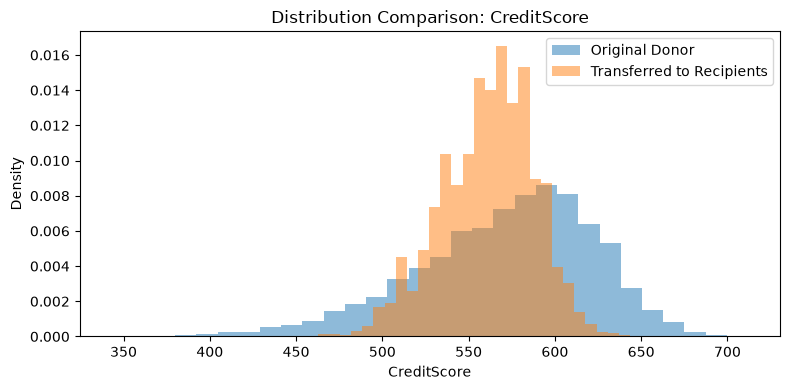

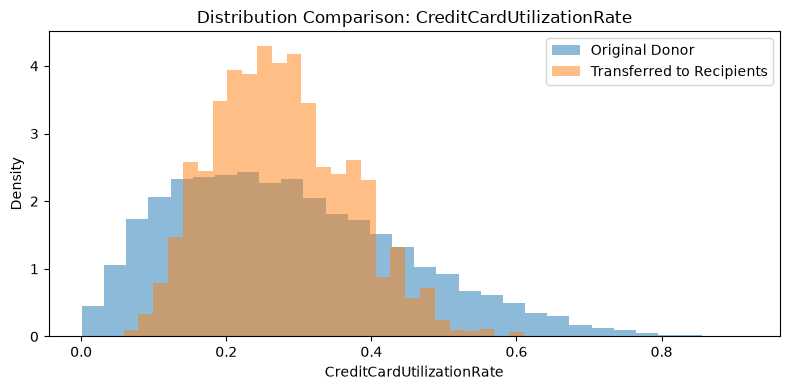

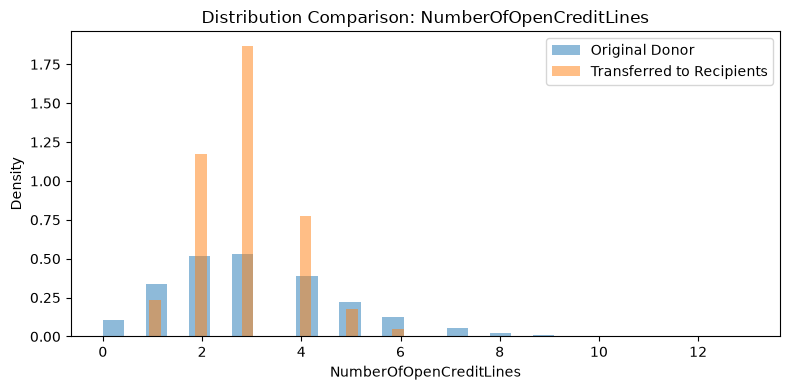

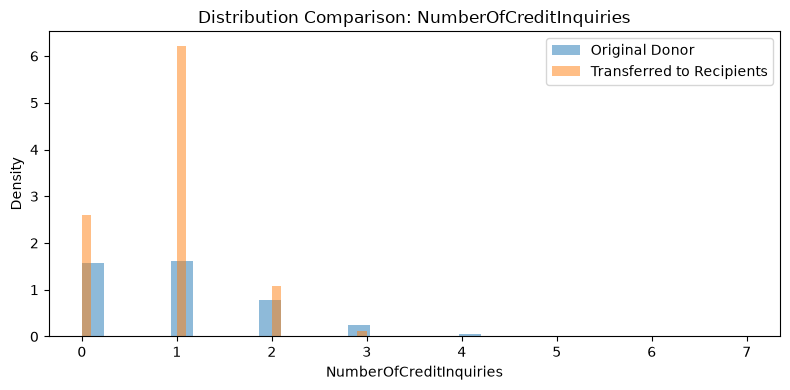

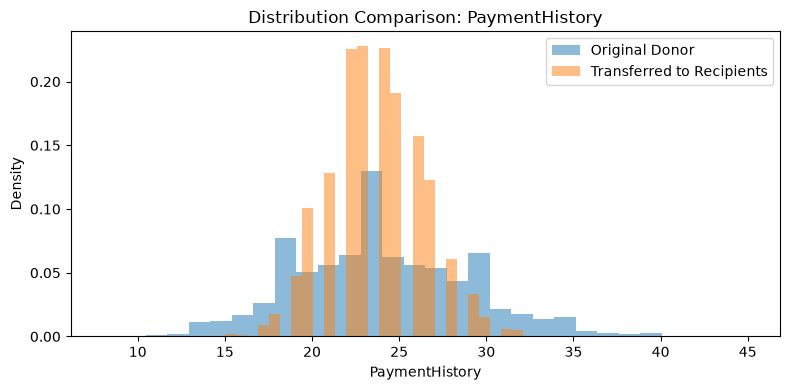

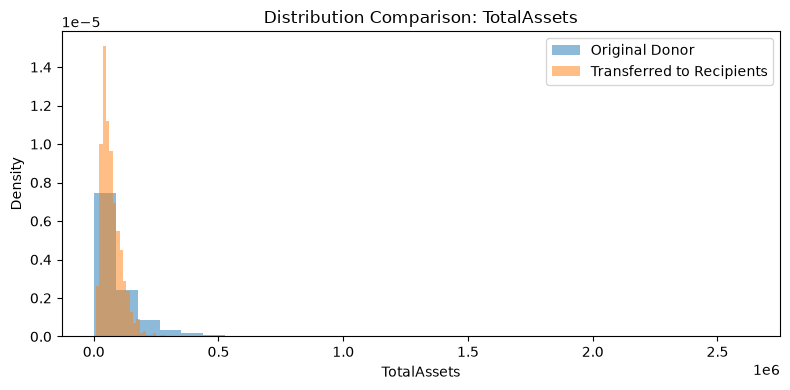

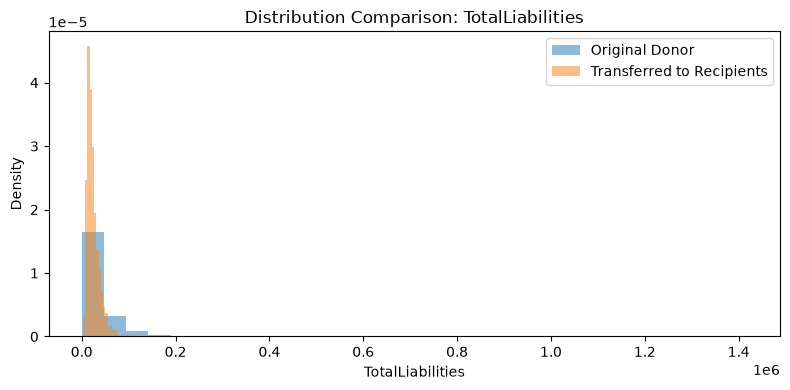

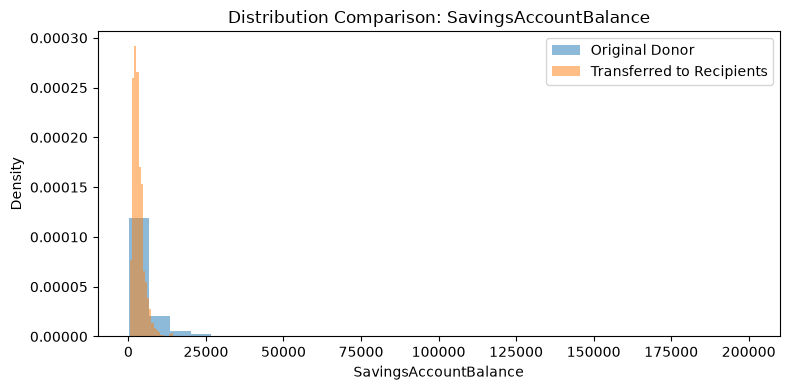

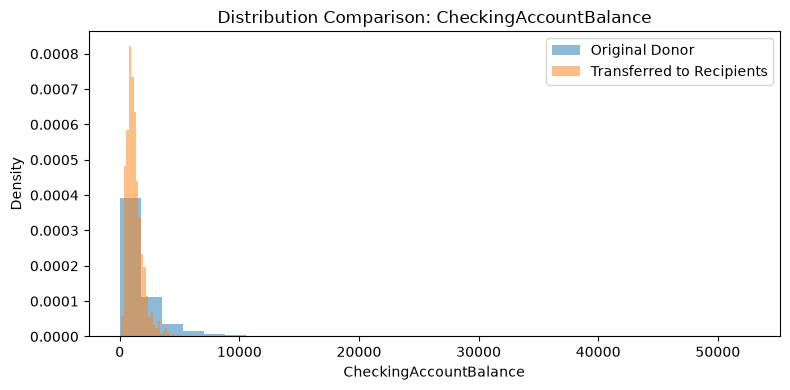

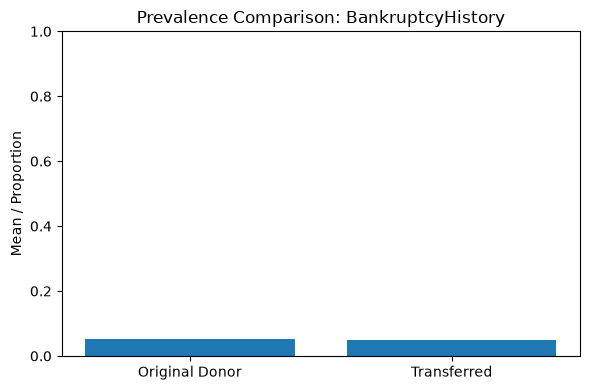

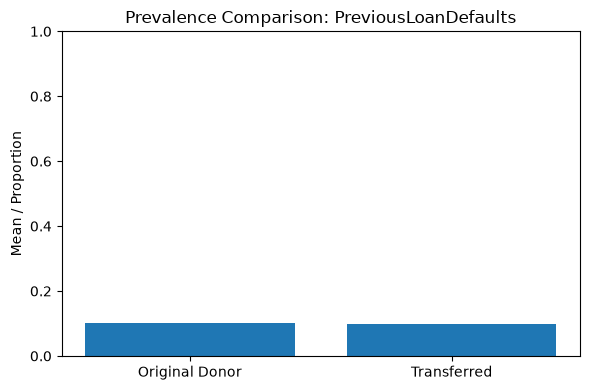


DISTRIBUTION COMPARISON COMPLETED.
Results saved to: D:\AI-Engineering\Loan_Default_Research\datasets\processed\fusion_distribution_validation.csv


In [30]:
# ============================================================
# TRANSFERRED DONOR FEATURE DISTRIBUTION VALIDATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

# Compare original donor distributions with features
# transferred to eligible training recipients.

eligible_fused = df_fused.loc[
    df_fused["fusion_eligible"]
].copy()

binary_features = [
    "BankruptcyHistory",
    "PreviousLoanDefaults"
]

distribution_results = []

for feature in candidate_features:

    # Identify corresponding aggregated feature
    if feature in binary_features:
        fused_column = f"donor_{feature}_proportion"
    else:
        fused_column = f"donor_{feature}_median"

    donor_values = df_donor[feature].dropna()
    fused_values = eligible_fused[fused_column].dropna()

    result = {
        "Feature": feature,
        "Donor_Mean": donor_values.mean(),
        "Fused_Mean": fused_values.mean(),
        "Donor_Median": donor_values.median(),
        "Fused_Median": fused_values.median(),
        "Donor_Std": donor_values.std(),
        "Fused_Std": fused_values.std(),
        "Donor_Count": len(donor_values),
        "Fused_Count": len(fused_values)
    }

    # Numerical features: compare distribution shapes using KS test
    if feature not in binary_features:

        ks_result = ks_2samp(
            donor_values,
            fused_values
        )

        result["KS_Statistic"] = ks_result.statistic
        result["KS_P_Value"] = max(
            ks_result.pvalue,
            np.finfo(float).tiny
        )
        result["Comparison_Type"] = "KS test"

    # Binary features: compare donor prevalence with
    # mean transferred donor proportions.
    else:

        donor_prevalence = donor_values.mean()
        transferred_prevalence = fused_values.mean()

        result["Donor_Prevalence"] = donor_prevalence
        result["Transferred_Prevalence"] = transferred_prevalence
        result["Absolute_Prevalence_Difference"] = abs(
            donor_prevalence - transferred_prevalence
        )
        result["Comparison_Type"] = "Prevalence comparison"

    distribution_results.append(result)


# ------------------------------------------------------------
# CREATE DISTRIBUTION COMPARISON TABLE
# ------------------------------------------------------------

distribution_comparison = pd.DataFrame(
    distribution_results
)

print("DONOR VS TRANSFERRED FEATURE DISTRIBUTIONS")

display(
    distribution_comparison.round(4)
)

# ------------------------------------------------------------
# VALIDATION CHECKS
# ------------------------------------------------------------

assert len(distribution_comparison) == 11
assert distribution_comparison["Donor_Count"].gt(0).all()
assert distribution_comparison["Fused_Count"].gt(0).all()

numerical_results = distribution_comparison[
    ~distribution_comparison["Feature"].isin(binary_features)
]

assert numerical_results["KS_P_Value"].notna().all()

binary_results = distribution_comparison[
    distribution_comparison["Feature"].isin(binary_features)
]

assert binary_results[
    "Absolute_Prevalence_Difference"
].notna().all()

print("\nALL 11 TRANSFERRED FEATURES VALIDATED.")

# ------------------------------------------------------------
# PLOT NUMERICAL FEATURE DISTRIBUTIONS
# ------------------------------------------------------------

for feature in candidate_features:

    if feature in binary_features:
        continue

    fused_column = f"donor_{feature}_median"

    plt.figure(figsize=(8, 4))

    plt.hist(
        df_donor[feature].dropna(),
        bins=30,
        alpha=0.5,
        density=True,
        label="Original Donor"
    )

    plt.hist(
        eligible_fused[fused_column].dropna(),
        bins=30,
        alpha=0.5,
        density=True,
        label="Transferred to Recipients"
    )

    plt.title(f"Distribution Comparison: {feature}")
    plt.xlabel(feature)
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# PLOT BINARY FEATURE PREVALENCE
# ------------------------------------------------------------

for feature in binary_features:

    fused_column = f"donor_{feature}_proportion"

    donor_prevalence = df_donor[feature].mean()
    transferred_prevalence = (
        eligible_fused[fused_column].mean()
    )

    plt.figure(figsize=(6, 4))

    plt.bar(
        ["Original Donor", "Transferred"],
        [donor_prevalence, transferred_prevalence]
    )

    plt.title(f"Prevalence Comparison: {feature}")
    plt.ylabel("Mean / Proportion")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# SAVE VALIDATION RESULTS
# ------------------------------------------------------------

distribution_path = (
    processed_dir / "fusion_distribution_validation.csv"
)

distribution_comparison.to_csv(
    distribution_path,
    index=False
)

print("\nDISTRIBUTION COMPARISON COMPLETED.")
print("Results saved to:", distribution_path)

In [31]:
# ==================================================
# RANDOM-DONOR PLACEBO DATASET GENERATION
# ==================================================

rng = np.random.default_rng(42)

binary_features = [
    "BankruptcyHistory",
    "PreviousLoanDefaults"
]

numerical_features = [
    feature for feature in candidate_features
    if feature not in binary_features
]

def create_random_donor_features(
    recipient_data,
    eligible_ids,
    rng
):
    random_aggregates = []

    for credit_idx in eligible_ids:

        # Get recipient's home ownership category
        category = str(
            recipient_data.loc[
                credit_idx, "person_home_ownership"
            ]
        ).upper()

        # Select donors from the same category
        available_donors = donor_match[
            donor_match["home_ownership"] == category
        ].index.to_numpy()

        if len(available_donors) < 5:
            raise ValueError(
                f"Not enough donors for category: {category}"
            )

        # Randomly select five distinct donors
        selected_indices = rng.choice(
            available_donors,
            size=5,
            replace=False
        )

        selected_donor_data = df_donor.loc[
            selected_indices, candidate_features
        ]

        # Aggregate numerical and binary features
        row = {}

        for feature in numerical_features:
            row[f"donor_{feature}_median"] = (
                selected_donor_data[feature].median()
            )

        for feature in binary_features:
            row[f"donor_{feature}_proportion"] = (
                selected_donor_data[feature].mean()
            )

        row["credit_index"] = credit_idx
        random_aggregates.append(row)

    return (
        pd.DataFrame(random_aggregates)
        .set_index("credit_index")
    )


# --------------------------------------------------
# CREATE RANDOM-DONOR TRAINING FEATURES
# --------------------------------------------------

random_train_features = create_random_donor_features(
    df_credit_train,
    accepted_ids,
    rng
)

# --------------------------------------------------
# CREATE RANDOM-DONOR TEST FEATURES
# --------------------------------------------------

random_test_features = create_random_donor_features(
    df_credit_test,
    test_accepted_ids,
    rng
)

# --------------------------------------------------
# REPLACE MATCHED DONOR FEATURES WITH RANDOM FEATURES
# --------------------------------------------------

random_fused_train = df_fused_model.drop(
    columns=donor_columns
).join(random_train_features)

random_fused_test = fused_test_model.drop(
    columns=donor_columns
).join(random_test_features)

# --------------------------------------------------
# VALIDATION
# --------------------------------------------------

assert len(random_fused_train) == len(df_fused_model)
assert len(random_fused_test) == len(fused_test_model)

assert random_fused_train["loan_status"].equals(
    df_fused_model["loan_status"]
)

assert random_fused_test["loan_status"].equals(
    fused_test_model["loan_status"]
)

assert random_fused_train["fusion_eligible"].equals(
    df_fused_model["fusion_eligible"]
)

assert random_fused_test["fusion_eligible"].equals(
    fused_test_model["fusion_eligible"]
)

assert random_fused_train.loc[
    ~random_fused_train["fusion_eligible"],
    donor_columns
].isna().all().all()

assert random_fused_test.loc[
    ~random_fused_test["fusion_eligible"],
    donor_columns
].isna().all().all()

assert random_fused_train.loc[
    random_fused_train["fusion_eligible"],
    donor_columns
].notna().all().all()

assert random_fused_test.loc[
    random_fused_test["fusion_eligible"],
    donor_columns
].notna().all().all()

# --------------------------------------------------
# SAVE PLACEBO DATASETS
# --------------------------------------------------

random_train_path = (
    processed_dir / "credit_risk_random_donor_train.csv"
)

random_test_path = (
    processed_dir / "credit_risk_random_donor_test.csv"
)

random_fused_train.to_csv(
    random_train_path,
    index=False
)

random_fused_test.to_csv(
    random_test_path,
    index=False
)

print("RANDOM-DONOR PLACEBO DATASETS CREATED")

print("\nTraining shape:", random_fused_train.shape)
print("Test shape:", random_fused_test.shape)

print(
    "\nRandom-donor training recipients:",
    random_fused_train["fusion_eligible"].sum()
)

print(
    "Random-donor test recipients:",
    random_fused_test["fusion_eligible"].sum()
)

print("\nTraining file:", random_train_path)
print("Test file:", random_test_path)

print("\nALL RANDOM-DONOR DATASET CHECKS PASSED.")

RANDOM-DONOR PLACEBO DATASETS CREATED

Training shape: (25932, 24)
Test shape: (6484, 24)

Random-donor training recipients: 24283
Random-donor test recipients: 6036

Training file: D:\AI-Engineering\Loan_Default_Research\datasets\processed\credit_risk_random_donor_train.csv
Test file: D:\AI-Engineering\Loan_Default_Research\datasets\processed\credit_risk_random_donor_test.csv

ALL RANDOM-DONOR DATASET CHECKS PASSED.


## Visualization of Statistical Data Fusion Results

Figure saved: D:\AI-Engineering\Loan_Default_Research\results\figures\Notebook_03_Fusion\Figure_1_Fifth_Nearest_Donor_Distances.png


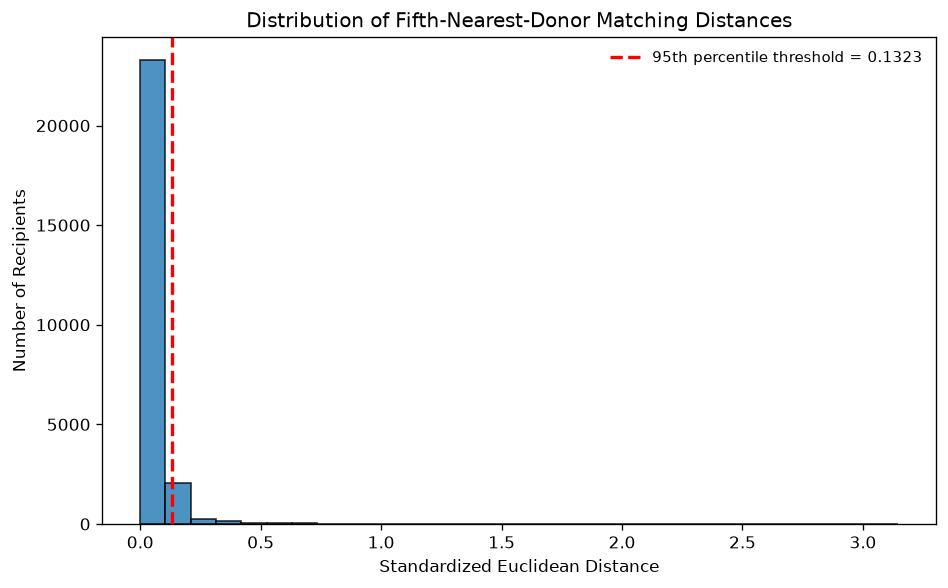

Figure saved: D:\AI-Engineering\Loan_Default_Research\results\figures\Notebook_03_Fusion\Figure_2_Donor_Reuse.png


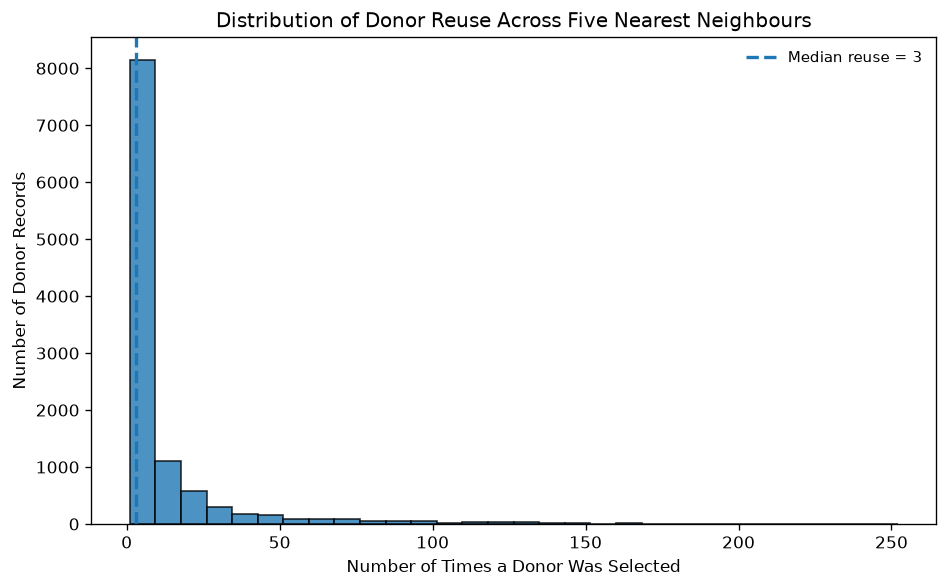

Figure saved: D:\AI-Engineering\Loan_Default_Research\results\figures\Notebook_03_Fusion\Figure_3_Common_Support_Coverage.png


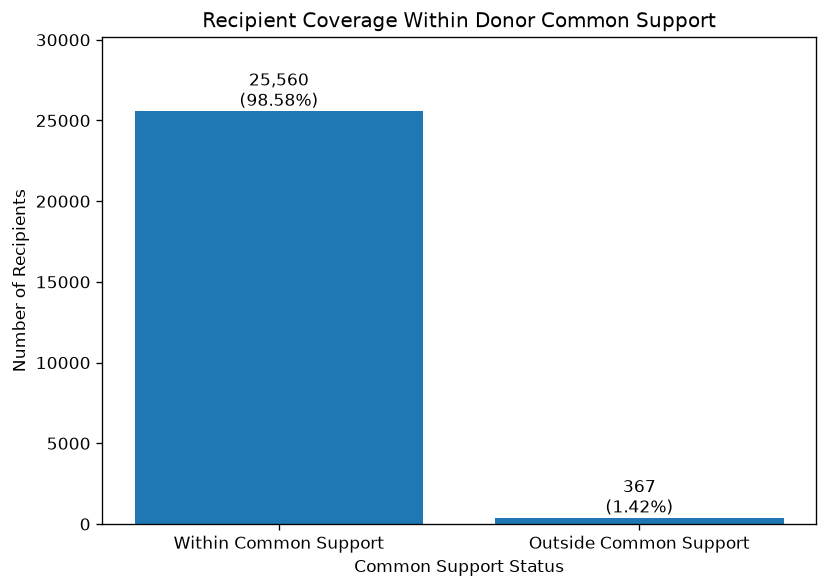

Figure saved: D:\AI-Engineering\Loan_Default_Research\results\figures\Notebook_03_Fusion\Figure_4_Fusion_Eligibility_Outcomes.png


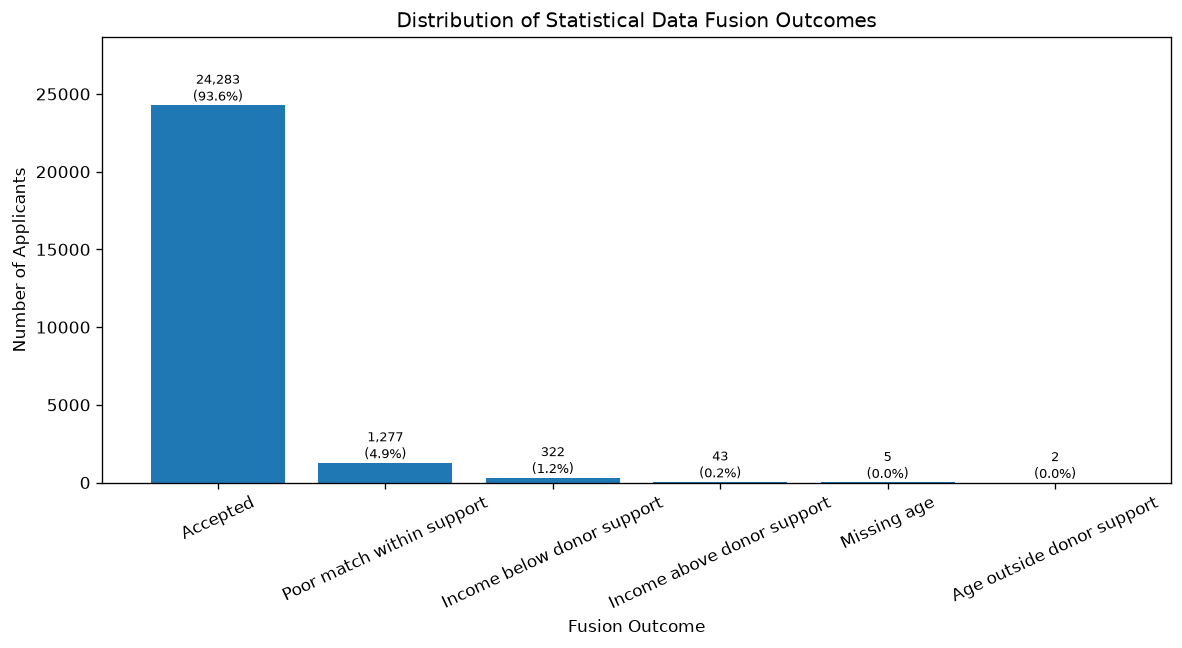


ALL DATA FUSION VISUALIZATIONS GENERATED SUCCESSFULLY

Saved figures:
Figure_1_Fifth_Nearest_Donor_Distances.png
Figure_2_Donor_Reuse.png
Figure_3_Common_Support_Coverage.png
Figure_4_Fusion_Eligibility_Outcomes.png

Figure directory: D:\AI-Engineering\Loan_Default_Research\results\figures\Notebook_03_Fusion


In [32]:
# ============================================================
# VISUALIZATION OF STATISTICAL DATA FUSION RESULTS
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Create output directory
results_dir = project_dir / "results"

figures_dir = (
    results_dir / "figures" / "Notebook_03_Fusion"
)
figures_dir.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.fontsize": 9
})


def save_figure(filename):
    plt.tight_layout()

    figure_path = figures_dir / f"{filename}.png"

    plt.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    print(f"Figure saved: {figure_path}")

    plt.show()
    plt.close()


# ============================================================
# FIGURE 1: NEAREST-NEIGHBOUR MATCHING DISTANCE DISTRIBUTION
# ============================================================

fifth_distances = matching_df.loc[
    matching_df["neighbor_rank"] == 5,
    "distance"
].dropna()

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    fifth_distances,
    bins=30,
    edgecolor="black",
    alpha=0.8
)

ax.axvline(
    threshold_95,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"95th percentile threshold = {threshold_95:.4f}"
)

ax.set_title("Distribution of Fifth-Nearest-Donor Matching Distances")
ax.set_xlabel("Standardized Euclidean Distance")
ax.set_ylabel("Number of Recipients")
ax.legend(frameon=False)

save_figure("Figure_1_Fifth_Nearest_Donor_Distances")


# ============================================================
# FIGURE 2: DONOR REUSE DISTRIBUTION
# ============================================================

donor_reuse = all_donor_usage[all_donor_usage > 0]

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    donor_reuse,
    bins=30,
    edgecolor="black",
    alpha=0.8
)

ax.axvline(
    donor_reuse.median(),
    linestyle="--",
    linewidth=2,
    label=f"Median reuse = {donor_reuse.median():.0f}"
)

ax.set_title("Distribution of Donor Reuse Across Five Nearest Neighbours")
ax.set_xlabel("Number of Times a Donor Was Selected")
ax.set_ylabel("Number of Donor Records")
ax.legend(frameon=False)

save_figure("Figure_2_Donor_Reuse")


# ============================================================
# FIGURE 3: COMMON-SUPPORT COVERAGE
# ============================================================

support_counts = support_check["both_in_range"].value_counts()

within_count = int(support_counts.get(True, 0))
outside_count = int(support_counts.get(False, 0))

support_labels = [
    "Within Common Support",
    "Outside Common Support"
]

support_values = [
    within_count,
    outside_count
]

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    support_labels,
    support_values
)

ax.set_title("Recipient Coverage Within Donor Common Support")
ax.set_xlabel("Common Support Status")
ax.set_ylabel("Number of Recipients")

ax.set_ylim(0, max(support_values) * 1.18)

for bar, value in zip(bars, support_values):
    percentage = value / sum(support_values) * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom"
    )

save_figure("Figure_3_Common_Support_Coverage")


# ============================================================
# FIGURE 4: FUSION ELIGIBILITY OUTCOMES
# ============================================================

outcome_counts = (
    eligibility_analysis["fusion_outcome"]
    .value_counts()
)

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.bar(
    outcome_counts.index,
    outcome_counts.values
)

ax.set_title("Distribution of Statistical Data Fusion Outcomes")
ax.set_xlabel("Fusion Outcome")
ax.set_ylabel("Number of Applicants")

ax.tick_params(
    axis="x",
    labelrotation=25
)

ax.set_ylim(0, outcome_counts.max() * 1.18)

for bar, value in zip(bars, outcome_counts.values):
    percentage = value / outcome_counts.sum() * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=8
    )

save_figure("Figure_4_Fusion_Eligibility_Outcomes")


# ============================================================
# FINAL OUTPUT
# ============================================================

print("\nALL DATA FUSION VISUALIZATIONS GENERATED SUCCESSFULLY")

print("\nSaved figures:")

for file in sorted(figures_dir.iterdir()):
    print(file.name)

print("\nFigure directory:", figures_dir)